# REVOTO | Exploración electoral por entidad federativa

**EDA reproducible · INE + contexto INEGI/CONAPO · 2009–2024**

Este cuaderno es un **reporte analítico**, no un proceso de transformación productivo. Cambia `ESTADO_SELECCIONADO` en la siguiente celda y ejecuta **Kernel → Restart & Run All**. Todos los cálculos, textos, fuentes, mapas y archivos de salida se reconstruyen para la entidad elegida.

**Preguntas rectoras.** ¿Cómo varía la participación a través de las elecciones? ¿Qué diferencias aparecen entre municipios, edades, sexos, tipos de sección y cohortes aproximadas? ¿Qué cobertura real tienen las fuentes? ¿Qué pantallas de REVOTO son posibles con la información observada?

> **Alcance y precauciones.** Las tasas usan `SUM(SV) / SUM(LN) - SUM(NS)` sobre la capa elegida. Los datos del proyecto pueden ser parciales: observar una entidad, un municipio o una sección **no equivale a cobertura oficial completa**. No se atribuyen motivaciones del voto a partir de correlaciones agregadas ni se interpreta `DEL` sin confirmar su diccionario y vigencia. Los códigos de sexo y `TIPOSEC` conservan sus etiquetas originales hasta validar el catálogo.

### Índice
1. Parámetros, librerías y contrato visual
2. Descubrimiento, carga y auditoría de calidad
3. Participación estatal e historia electoral
4. Dispersión y rankings municipales
5. Sexo, tipo de sección, edad y cohortes aproximadas
6. Geografía municipal
7. Contexto INEGI–CONAPO
8. Storytelling, cobertura de wireframes y resumen ejecutivo
9. Exportación y bitácora

## 0 · Parámetros de ejecución

La **única selección obligatoria es `ESTADO_SELECCIONADO`**: admite nombre (con o sin acentos), abreviatura simple para CDMX o clave INEGI de dos dígitos. Los patrones de ruta se reconstruyen con esa clave. Si tu repositorio tiene otras convenciones, modifica las tres plantillas, no cada bloque del análisis.

In [51]:
ESTADO_SELECCIONADO = "Querétaro"  # Ej.: "Jalisco", "Ciudad de México", "20", 9

# Ubicación opcional si Jupyter no se abre dentro del repositorio REVOTO.
ROOT_MANUAL = None  # Ej.: r"C:/Users/usuario/proyectos/ReVoto"
PATRON_ELECTORAL = "data/processed/canonical/hecho_participacion/edo={edo}/anio=*/hechos.parquet"
PATRON_CONTEXTO = "data/processed/full_context/edo={edo}/anio=*/municipios.parquet"
PATRON_GEOMETRIA = "apps/web/public/data/geometria/edo={edo}/municipios.geojson"

ANIOS_ESPERADOS = (2009, 2012, 2015, 2018, 2021, 2024)
UMBRAL_LN_EXPLORATORIO = 1000  # Solo para gráficos comparativos; NO es RN-05.
ANIO_MAPA = None               # None = último año realmente observado.
EDAD_TOPE_ABIERTA = None       # Ej.: 90, SOLO si el diccionario acredita «90 y más».
EXPORTAR_FIGURAS = True
MOSTRAR_TABLAS = True

# No infieras sexo ni sección por el número de código: completar solo con diccionario oficial.
ETIQUETAS_SEXO = {}            # Ejemplo tras verificar: {"1": "...", "2": "..."}
ETIQUETAS_TIPOSEC = {}
# Evita equivalencias implícitas entre cartografías de vigencias distintas.
ANIO_REFERENCIA_GEOMETRIA = None

In [52]:
from __future__ import annotations
import os, sys, glob, re, unicodedata, platform, json, warnings
from pathlib import Path
from datetime import datetime, timezone

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Rectangle
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display, Markdown

try:
    import seaborn as sns
except ImportError:
    sns = None  # Los gráficos esenciales usan Matplotlib.
try:
    import geopandas as gpd
except ImportError:
    gpd = None  # Solo afecta las coropletas reales.

ESTADOS = {
 1:"Aguascalientes",2:"Baja California",3:"Baja California Sur",4:"Campeche",
 5:"Coahuila",6:"Colima",7:"Chiapas",8:"Chihuahua",9:"Ciudad de México",
 10:"Durango",11:"Guanajuato",12:"Guerrero",13:"Hidalgo",14:"Jalisco",
 15:"México",16:"Michoacán",17:"Morelos",18:"Nayarit",19:"Nuevo León",
 20:"Oaxaca",21:"Puebla",22:"Querétaro",23:"Quintana Roo",24:"San Luis Potosí",
 25:"Sinaloa",26:"Sonora",27:"Tabasco",28:"Tamaulipas",29:"Tlaxcala",
 30:"Veracruz",31:"Yucatán",32:"Zacatecas"
}
# Únicamente referencia de control para Oaxaca (570 municipios), NO una inferencia
# de cobertura del dataset ni un catálogo nacional mantenido en este notebook.
MUNICIPIOS_ESPERADOS_VERIFICADOS = {20:570}

def _fold(text):
    return ''.join(c for c in unicodedata.normalize('NFKD', str(text).strip().casefold()) if not unicodedata.combining(c))

def estado_resolver(valor):
    if str(valor).strip().isdigit():
        codigo = int(valor)
    else:
        alias = {"cdmx":9, "df":9, "estado de mexico":15, "edomex":15,
                 "coahuila de zaragoza":5, "michoacan de ocampo":16,
                 "veracruz de ignacio de la llave":30}
        mapa = {_fold(nombre): clave for clave, nombre in ESTADOS.items()}
        mapa.update(alias)
        codigo = mapa.get(_fold(valor))
    if codigo not in ESTADOS:
        raise ValueError(f"Estado desconocido: {valor!r}. Opciones: {list(ESTADOS.values())}")
    return codigo, ESTADOS[codigo]

CLAVE_ESTADO, NOMBRE_ESTADO = estado_resolver(ESTADO_SELECCIONADO)
EDO = f"{CLAVE_ESTADO:02d}"

def hallar_raiz():
    if ROOT_MANUAL:
        return Path(ROOT_MANUAL).expanduser().resolve()
    if os.environ.get('REVOTO_REPO_ROOT'):
        return Path(os.environ['REVOTO_REPO_ROOT']).expanduser().resolve()
    actual = Path.cwd().resolve()
    for p in (actual, *actual.parents):
        if (p/'apps/pipeline').exists() and (p/'data').exists():
            return p
    return actual

RAIZ = hallar_raiz()
SALIDA = RAIZ / 'apps/pipeline/reportes/eda_outputs' / f'edo={EDO}'
FIGURAS = SALIDA / 'figuras'
SALIDA.mkdir(parents=True, exist_ok=True)
if EXPORTAR_FIGURAS:
    FIGURAS.mkdir(parents=True, exist_ok=True)

print(f'Entidad: {NOMBRE_ESTADO} ({EDO}) | repositorio: {RAIZ}')
print(f'Python: {platform.python_version()} | DuckDB: {duckdb.__version__} | Pandas: {pd.__version__}')
print(f'Exportes aislados por estado: {SALIDA}')

Entidad: Querétaro (22) | repositorio: D:\Almacenamiento\CodingLab\projects\personal\ReVoto
Python: 3.14.8 | DuckDB: 1.5.6 | Pandas: 3.0.6
Exportes aislados por estado: D:\Almacenamiento\CodingLab\projects\personal\ReVoto\apps\pipeline\reportes\eda_outputs\edo=22


### 0.1 · Sistema gráfico REVOTO

Todas las láminas reutilizan el mismo encabezado de marca, proporciones, etiquetas y pie de procedencia; las dos o tres subgráficas tienen **propósitos complementarios** y cada comparación usa un denominador explícito. Los colores vino y azul representan series contrastantes, nunca una clasificación electoral ni partidista.

In [53]:
VINO = '#FF2D94'
VINO_OSCURO = '#C8106E'
VINO_CLARO = '#FFE3F1'
AZUL = '#933D82'
AZUL_CLARO = '#AABDD4'
VERDE = '#8495FF'
AMARILLO = '#E4A83A'
MORADO = '#826093'
GRIS = '#595959'
GRIS_SEC = '#707B8E'
REJILLA = '#DAD8D7'
COLORES = [VINO, AZUL, VERDE, AMARILLO, MORADO, '#BC6C74', '#7C887C']

plt.rcParams.update({
    'figure.facecolor':'white', 'axes.facecolor':'white', 'savefig.facecolor':'white',
    'font.family':'DejaVu Sans', 'font.size':10, 'axes.titlesize':12,
    'axes.labelcolor':GRIS, 'text.color':GRIS, 'xtick.color':GRIS_SEC,
    'ytick.color':GRIS_SEC, 'grid.color':REJILLA, 'grid.alpha':0.5,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.spines.bottom':False, 'axes.spines.left':False,
    'figure.dpi':115, 'savefig.dpi':180
})

def limpiar_eje(ax, eje='y'):
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, pad=5)
    if eje:
        ax.grid(axis=eje, color=REJILLA, alpha=.5, linewidth=.8)
    return ax

def pagina(titulo, subtitulo, paneles=2, ancho=None, fuente='REVOTO · capa canónica electoral; elaboración propia.'):
    ancho = ancho or (17 if paneles==3 else 15.8)
    fig, axs = plt.subplots(1, paneles, figsize=(ancho, 6.25))
    fig.patch.set_facecolor('white')
    fig.subplots_adjust(left=.065, right=.975, top=.73, bottom=.145, wspace=.27)
    fig.add_artist(Rectangle((.018,.960),.055,.018, transform=fig.transFigure,
                             facecolor=VINO, edgecolor='none', clip_on=False))
    fig.add_artist(plt.Line2D([.018,.985],[.960,.960], transform=fig.transFigure,
                               color=VINO, lw=1.1))
    fig.text(.018,.908, titulo, fontsize=19, weight='bold', color=GRIS, va='top')
    fig.text(.018,.824,subtitulo, fontsize=10.5, color=GRIS, alpha=.88, va='top',wrap=True)
    fig.text(.018,.035, f'Fuente: {fuente}', fontsize=8.3, color=GRIS, alpha=.65)
    for ax in np.atleast_1d(axs):
        limpiar_eje(ax)
    return fig, np.atleast_1d(axs)

def cerrar(fig, archivo):
    if EXPORTAR_FIGURAS:
        fig.savefig(FIGURAS/f'{archivo}.png', dpi=180, facecolor='white')
    plt.show()
    plt.close(fig)

def porciento(ax, eje='y', decimales=0):
    (ax.yaxis if eje=='y' else ax.xaxis).set_major_formatter(mtick.PercentFormatter(100, decimals=decimales))

def mostrar(df, n=15):
    if MOSTRAR_TABLAS:
        display(df.head(n))

def safe_rate(votos, lista):
    # Nunca promediar tasas de filas; faltantes no se sustituyen por cero.
    return np.where(pd.to_numeric(lista,errors='coerce')>0, votos/lista, np.nan)

def nota(texto):
    display(Markdown(f'> **Nota de interpretación.** {texto}'))

ARCHIVOS_SALIDA = []

## 1 · Fuentes, carga y control de cobertura

Se consultan **solo las particiones del estado elegido**. El notebook utiliza DuckDB sobre Parquet sin materializar millones de filas en pandas. No se infiere el nombre de la columna: se inspecciona el esquema y se aplica un mapa de equivalencias explícito. Si no existe la partición, el cuaderno se detiene con un mensaje claro, sin generar cifras de sustitución.

In [54]:
PATRON = str(RAIZ / PATRON_ELECTORAL.format(edo=EDO))
ARCHIVOS_ELECTORALES = sorted(glob.glob(PATRON))
if not ARCHIVOS_ELECTORALES:
    raise FileNotFoundError(
        f'Sin datos electorales para {NOMBRE_ESTADO} ({EDO}). Se buscó: {PATRON}\n'
        'Comprueba REVOTO_REPO_ROOT / ROOT_MANUAL y PATRON_ELECTORAL. '
        'No se generan resultados sintéticos.'
    )

con = duckdb.connect(':memory:')
con.execute('PRAGMA threads=4')

def lit(texto): return "'"+str(texto).replace("'","''")+"'"
def ident(nombre): return '"'+str(nombre).replace('"','""')+'"'

# Lista explícita de archivos: no mezclar entidades ni depender del glob de otras capas.
paths_sql = '['+','.join(lit(p) for p in ARCHIVOS_ELECTORALES)+']'
TABLA_BRUTA = f'read_parquet({paths_sql}, union_by_name=true, hive_partitioning=false)'
ESQUEMA = con.execute(f'DESCRIBE SELECT * FROM {TABLA_BRUTA}').fetchdf()
COLUMNAS = set(ESQUEMA.column_name)
ALIAS = {
    'anio':('AELEC','ALEC','anio','anio_eleccion'),
    'estado':('EDOCVE','edo','estado'),
    'municipio':('MPIOCVE','municipio_cve'),
    'seccion':('SECCION','seccion'),
    'sexo':('SEXO','sexo'), 'edad':('EDAD','edad'),
    'tiposec':('TIPOSEC','tipo_seccion'),
    'distrito_local':('DEL','distrito_local'),
    'distrito_federal':('DEF','distrito_federal'),
    'ln':('LN','lista_nominal'), 'sv':('SV','votantes'),
    'nv':('NV',), 'ns':('NS',)
}
MAPEO = {rol:next((c for c in opciones if c in COLUMNAS), None) for rol,opciones in ALIAS.items()}
CRITICOS = ('anio','estado','municipio','seccion','ln','sv')
faltan = [r for r in CRITICOS if MAPEO[r] is None]
if faltan:
    raise ValueError(f'Faltan columnas críticas {faltan} en {PATRON}. Esquema: {sorted(COLUMNAS)}')

# Normalización virtual: las tablas productivas nunca se reescriben.
def expr(rol):
    col = MAPEO.get(rol)
    return f'TRY_CAST({ident(col)} AS BIGINT)' if col else 'NULL::BIGINT'

campos = ', '.join(f'{expr(rol)} AS {rol}' for rol in ALIAS)
con.execute(f'''
    CREATE VIEW electoral AS
    SELECT {campos} FROM {TABLA_BRUTA}
    WHERE TRY_CAST({ident(MAPEO['estado'])} AS INTEGER) = {CLAVE_ESTADO}
''')
procedencia = pd.DataFrame({
    'atributo':['estado','archivos_parquet','ruta_origen','contexto','geometria','generado_utc'],
    'valor':[f'{NOMBRE_ESTADO} ({EDO})',len(ARCHIVOS_ELECTORALES),PATRON,
            str(RAIZ/PATRON_CONTEXTO.format(edo=EDO)),
            str(RAIZ/PATRON_GEOMETRIA.format(edo=EDO)),datetime.now(timezone.utc).isoformat()]
})
mostrar(procedencia,10)
mostrar(pd.DataFrame({'rol':list(MAPEO),'columna_fuente':list(MAPEO.values())}),20)

,atributo,valor
0,estado,Querétaro (22)
1,archivos_parquet,6
2,ruta_origen,D:\Almacenamiento\CodingLab\projects\personal\...
3,contexto,D:\Almacenamiento\CodingLab\projects\personal\...
4,geometria,D:\Almacenamiento\CodingLab\projects\personal\...
5,generado_utc,2026-10-12T23:20:15.858030+00:00


,rol,columna_fuente
0,anio,AELEC
1,estado,EDOCVE
2,municipio,MPIOCVE
3,seccion,SECCION
4,sexo,SEXO
5,edad,EDAD
6,tiposec,TIPOSEC
7,distrito_local,DEL
8,distrito_federal,DEF
9,ln,LN


### 1.1 · Auditoría de calidad y granularidad

- **Cobertura observada:** años, municipios y pares `(municipio, sección)` presentes. Los códigos de sección **no** son claves globales por sí solos.
- **Integridad:** nulos, números negativos, `SV > LN`, lista cero y duplicados al grano analítico.
- **Interpretación:** un registro presente no acredita que exista el universo completo; aquí no se reconstruyen denominadores faltantes. `NV` y `NS` se auditan, pero no se suman automáticamente a `SV` o `LN` porque requieren definiciones verificadas.

In [55]:
calidad = con.execute('''
SELECT COUNT(*) filas, COUNT(DISTINCT anio) anios_distintos,
       COUNT_IF(anio IS NULL) anio_nulo, COUNT_IF(municipio IS NULL) municipio_nulo,
       COUNT_IF(seccion IS NULL) seccion_nula, COUNT_IF(sexo IS NULL) sexo_nulo,
       COUNT_IF(edad IS NULL) edad_nula, COUNT_IF(ln IS NULL) ln_nula,
       COUNT_IF(sv IS NULL) sv_nulo, COUNT_IF(ln < 0) ln_negativa,
       COUNT_IF(sv < 0) sv_negativo, COUNT_IF(ln = 0) ln_cero,
       COUNT_IF(sv > ln) sv_supera_ln, COUNT_IF(edad < 0) edad_negativa,
       COUNT(*) - COUNT(DISTINCT (anio,estado,municipio,seccion,sexo,edad,tiposec,distrito_local,distrito_federal))
       AS filas_excedentes_grano_ampliado
FROM electoral
''').fetchdf()

cobertura = con.execute('''
SELECT anio, COUNT(*) filas, COUNT(DISTINCT municipio) municipios,
       COUNT(DISTINCT (municipio,seccion)) secciones_municipales,
       COUNT(DISTINCT sexo) codigos_sexo, COUNT(DISTINCT tiposec) tipos_seccion,
       SUM(ln) ln, SUM(sv) sv
FROM electoral WHERE anio IS NOT NULL
GROUP BY anio ORDER BY anio
''').fetchdf()

mostrar(calidad.T.reset_index().rename(columns={'index':'control',0:'valor'}),30)
mostrar(cobertura,15)
ANIOS_OBSERVADOS = sorted(cobertura.anio.dropna().astype(int).unique().tolist())
ANIO_FINAL = max(ANIOS_OBSERVADOS) if ANIOS_OBSERVADOS else None
AUSENTES = sorted(set(ANIOS_ESPERADOS)-set(ANIOS_OBSERVADOS))
conteo_ref = MUNICIPIOS_ESPERADOS_VERIFICADOS.get(CLAVE_ESTADO)
print('Años esperados sin partición observada:', AUSENTES or 'ninguno')
if conteo_ref:
    print(f'Municipios con datos en {ANIO_FINAL}: {int(cobertura.loc[cobertura.anio.eq(ANIO_FINAL),"municipios"].iloc[0])} / {conteo_ref} municipios de referencia; NO equivale a cobertura total.')

,control,valor
0,filas,706806.0
1,anios_distintos,6.0
2,anio_nulo,0.0
3,municipio_nulo,0.0
4,seccion_nula,0.0
5,sexo_nulo,0.0
6,edad_nula,0.0
7,ln_nula,0.0
8,sv_nulo,0.0
9,ln_negativa,0.0


,anio,filas,municipios,secciones_municipales,codigos_sexo,tipos_seccion,ln,sv
0,2009,103566,18,761,2,0,1154593.0,671180.0
1,2012,108198,18,806,2,0,1231488.0,810653.0
2,2015,116886,18,860,2,0,1413798.0,763374.0
3,2018,119031,18,860,2,0,1582958.0,962418.0
4,2021,124751,18,891,2,0,1736388.0,865774.0
5,2024,134374,18,953,3,0,1899053.0,1131708.0


Años esperados sin partición observada: ninguno


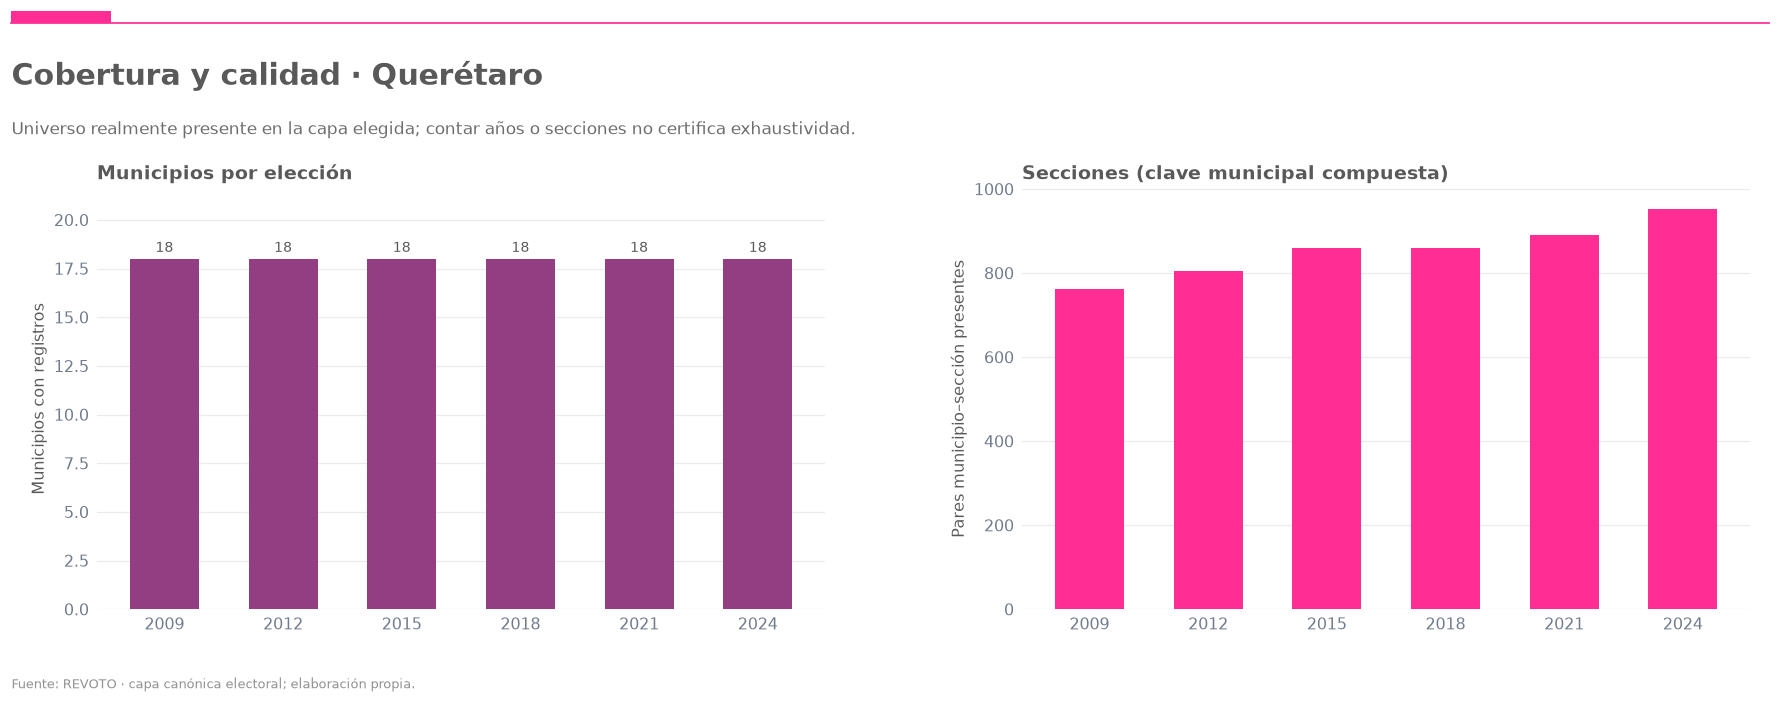

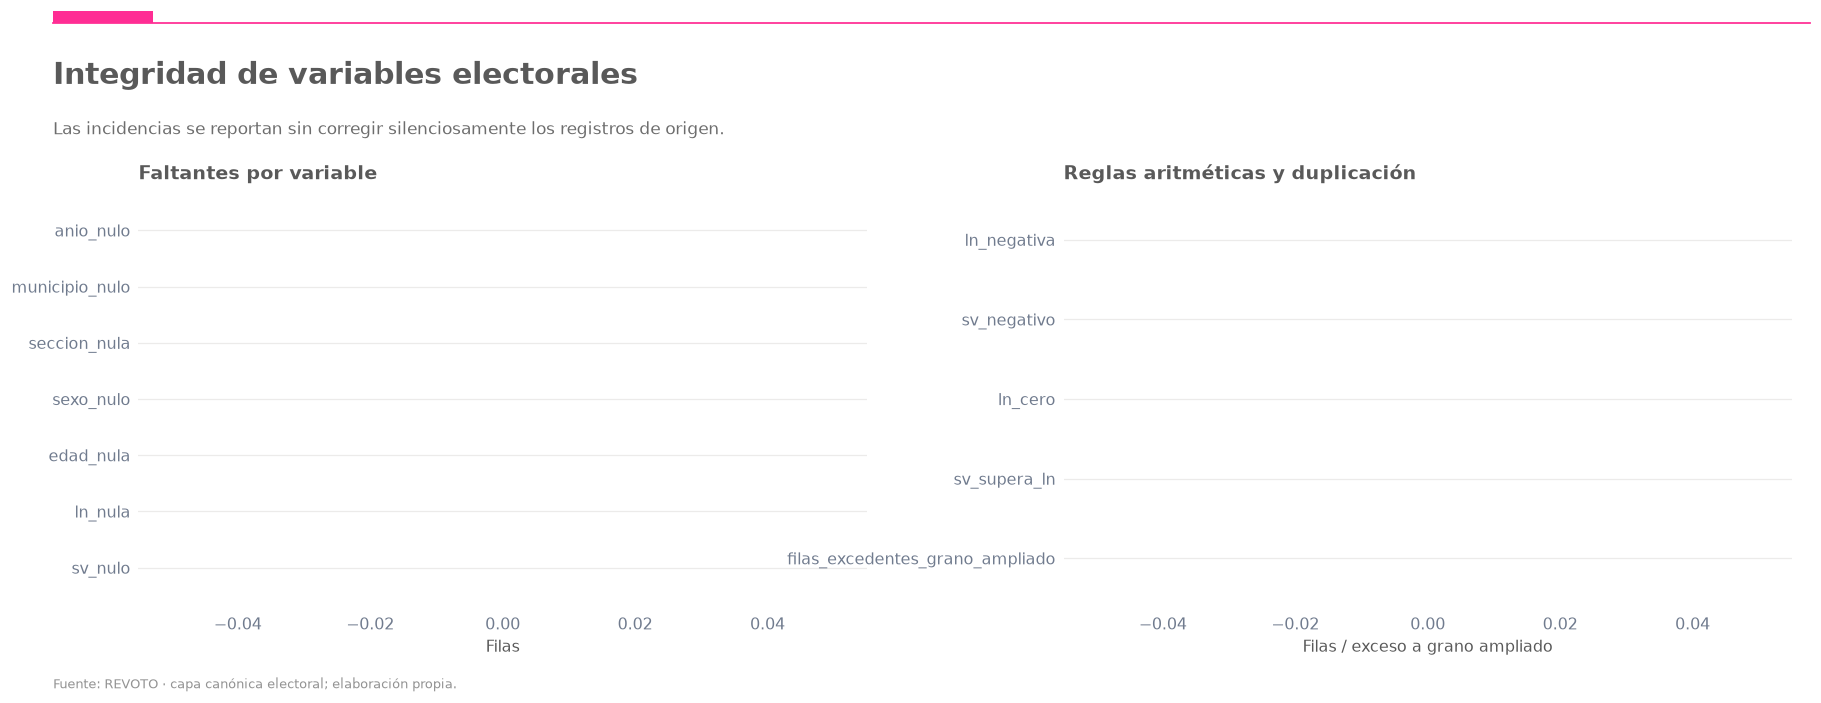

> **Nota de interpretación.** El umbral RN-05 no se ha aplicado aquí: los gráficos son exploratorios. Revisar de forma independiente representatividad, código electoral, vigencias geográficas y política de publicación antes de alimentar el frontend.

In [56]:
fig,axs=pagina(f'Cobertura y calidad · {NOMBRE_ESTADO}',
 'Universo realmente presente en la capa elegida; contar años o secciones no certifica exhaustividad.')
ax1,ax2=axs
ax1.bar(cobertura.anio.astype(str), cobertura.municipios, color=AZUL, width=.58)
for x,n in enumerate(cobertura.municipios): ax1.text(x,n+max(cobertura.municipios)*.02,str(int(n)),ha='center',fontsize=9)
ax1.set_title('Municipios por elección',loc='left',weight='bold')
ax1.set_ylabel('Municipios con registros')
ax1.set_ylim(0,max(cobertura.municipios.max()*1.20,1))
ax2.bar(cobertura.anio.astype(str), cobertura.secciones_municipales, color=VINO, width=.58)
ax2.set_title('Secciones (clave municipal compuesta)',loc='left',weight='bold')
ax2.set_ylabel('Pares municipio–sección presentes')
cerrar(fig,'01_cobertura_territorial')

checks = pd.DataFrame([{'control':k,'conteo':int(calidad.loc[0,k])} for k in
    ['anio_nulo','municipio_nulo','seccion_nula','sexo_nulo','edad_nula','ln_nula','sv_nulo',
     'ln_negativa','sv_negativo','ln_cero','sv_supera_ln','filas_excedentes_grano_ampliado']])
fig,axs=pagina('Integridad de variables electorales',
 'Las incidencias se reportan sin corregir silenciosamente los registros de origen.')
ax1,ax2=axs
nulos=checks.iloc[:7]
ax1.barh(nulos.control[::-1],nulos.conteo[::-1],color=VINO_CLARO)
ax1.set_title('Faltantes por variable',loc='left',weight='bold')
ax1.set_xlabel('Filas')
invalidos=checks.iloc[7:]
ax2.barh(invalidos.control[::-1],invalidos.conteo[::-1],color=AZUL)
ax2.set_title('Reglas aritméticas y duplicación',loc='left',weight='bold')
ax2.set_xlabel('Filas / exceso a grano ampliado')
cerrar(fig,'02_auditoria_integridad')
nota('El umbral RN-05 no se ha aplicado aquí: los gráficos son exploratorios. Revisar de forma independiente representatividad, código electoral, vigencias geográficas y política de publicación antes de alimentar el frontend.')

### 1.2 · Conciliación opcional entre capas (L1–L4)

Si existen otras capas consolidadas, aquí se puede **cotejar** su suma de numeradores, denominadores y filas por elección contra el canónico. No se mezclan sin revisión esquemas que puedan representar granos diferentes. Por defecto está vacío: no se inventa una conciliación a partir de archivos no proporcionados. El código no modifica esas capas.

In [57]:
# Opcional. Cada elemento describe una fuente adicional real y columnas YA auditadas.
# Ej.: 'staging': {'glob':'data/staging/.../*.parquet',
#                   'year':'AELEC','state':'EDOCVE','sv':'SV','ln':'LN'}
CAPAS_PARA_COTEJO = {}

comparacion_capas = hist[['anio','votos','lista_nominal','tasa']].copy() if 'hist' in globals() else pd.DataFrame()
# La comparación se ejecuta después de la construcción del histórico en §2.
def reconciliar_capas(registros,canonica):
    filas=[canonica[['anio','votos','lista_nominal','tasa']].assign(capa='canonical')]
    for nombre,cfg in registros.items():
        patron=str(RAIZ/cfg['glob'].format(edo=EDO))
        archivos=sorted(glob.glob(patron))
        if not archivos:
            print(f'Capa {nombre} no disponible: {patron}')
            continue
        tabla='read_parquet(['+','.join(lit(p) for p in archivos)+'], union_by_name=true)'
        cols=set(con.execute(f'DESCRIBE SELECT * FROM {tabla}').fetchdf().column_name)
        requeridas=[cfg.get(k) for k in ('year','state','sv','ln')]
        if any(v not in cols for v in requeridas):
            print(f'Mapeos inválidos en capa {nombre}; faltan columnas o roles: {requeridas}')
            continue
        y,e,n,d=map(lambda v:ident(cfg[v]),('year','state','sv','ln'))
        sql=(f'SELECT TRY_CAST({y} AS INTEGER) anio, SUM(TRY_CAST({n} AS DOUBLE)) votos, '
             f'SUM(TRY_CAST({d} AS DOUBLE)) lista_nominal FROM {tabla} '
             f'WHERE TRY_CAST({e} AS INTEGER)=? GROUP BY 1 ORDER BY 1')
        otro=con.execute(sql,[CLAVE_ESTADO]).fetchdf()
        otro['tasa']=safe_rate(otro.votos,otro.lista_nominal)
        filas.append(otro.assign(capa=nombre))
    return pd.concat(filas,ignore_index=True)

## 2 · Participación histórica

La **tasa estatal** no es el promedio de porcentajes municipales. Se calcula agrupando todos los registros que pertenecen al estado y año: $100\times\sum SV/\sum LN$. El cambio entre elecciones está medido en **puntos porcentuales (pp)**, no en crecimiento porcentual relativo. Los años presidenciales/intermedios no se etiquetan automáticamente sin un catálogo de tipo de elección válido.

,anio,votos,lista_nominal,filas,tasa,cambio_pp,cambio_relativo_pct
0,2009,671180.0,1154593.0,103566,0.581313,NaN,NaN
1,2012,810653.0,1231488.0,108198,0.658271,7.695806,13.238660
2,2015,763374.0,1413798.0,116886,0.539946,-11.832554,-17.975198
3,2018,962418.0,1582958.0,119031,0.607987,6.804148,12.601544
4,2021,865774.0,1736388.0,124751,0.498606,-10.938077,-17.990641
5,2024,1131708.0,1899053.0,134374,0.595933,9.732651,19.519712


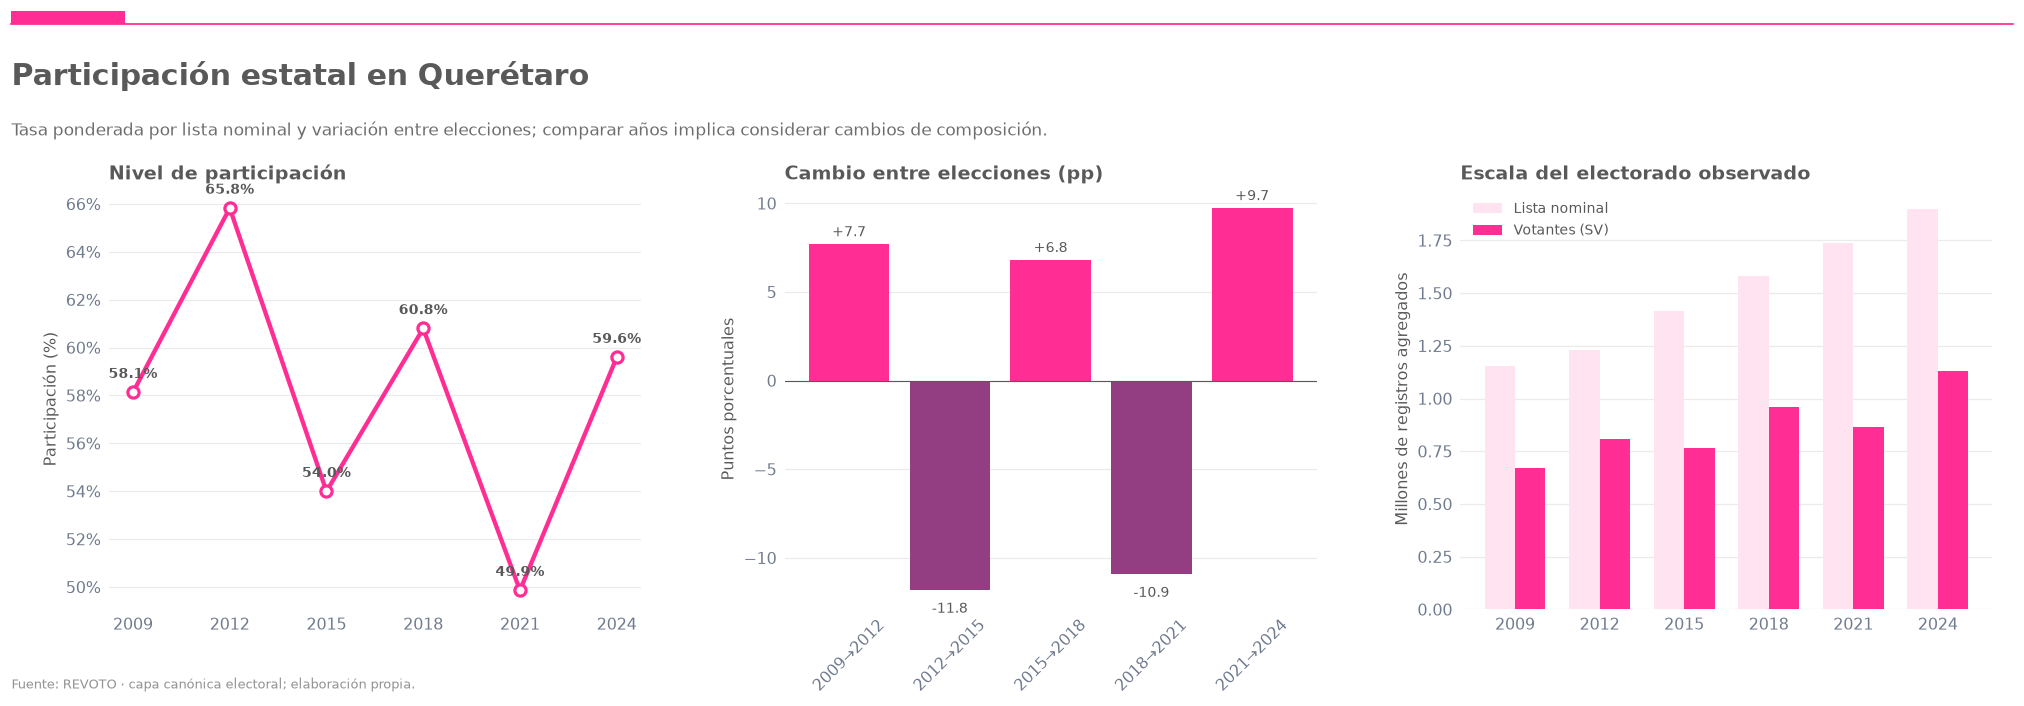

> **Nota de interpretación.** Máximo observado: **2012 (65.8%)**; mínimo: **2021 (49.9%)**. El último cambio es **+9.7 pp**. Estos valores describen exclusivamente las filas disponibles en la fuente.

In [58]:
hist = con.execute('''
SELECT anio, SUM(sv) AS votos, SUM(ln) AS lista_nominal, COUNT(*) filas
FROM electoral WHERE anio IS NOT NULL GROUP BY 1 ORDER BY 1
''').fetchdf()
hist['tasa'] = safe_rate(hist.votos,hist.lista_nominal)
hist['cambio_pp'] = hist.tasa.diff()*100
hist['cambio_relativo_pct'] = hist.tasa.pct_change(fill_method=None)*100
mostrar(hist,15)
fig,axs=pagina(f'Participación estatal en {NOMBRE_ESTADO}',
 'Tasa ponderada por lista nominal y variación entre elecciones; comparar años implica considerar cambios de composición.',3,18)
a,b,c=axs
anos=hist.anio.astype(int)
a.plot(anos,hist.tasa*100,color=VINO,marker='o',markersize=7,linewidth=2.7,markerfacecolor='white',markeredgewidth=2)
for x,y in zip(anos,hist.tasa*100):
    if np.isfinite(y): a.annotate(f'{y:.1f}%',(x,y),xytext=(0,9),textcoords='offset points',ha='center',fontsize=9,weight='bold')
a.set_xticks(anos)
a.set_ylabel('Participación (%)'); porciento(a)
a.set_title('Nivel de participación',loc='left',weight='bold')
cambios=hist.iloc[1:]
b.bar([f'{int(x)}→{int(y)}' for x,y in zip(anos[:-1],anos[1:])], cambios.cambio_pp,
      color=[VINO if v>=0 else AZUL for v in cambios.cambio_pp])
b.axhline(0,color=GRIS,linewidth=.7)
b.tick_params(axis='x',labelrotation=45)
b.set_title('Cambio entre elecciones (pp)',loc='left',weight='bold')
b.set_ylabel('Puntos porcentuales')
for j,v in enumerate(cambios.cambio_pp):
    if np.isfinite(v): b.annotate(f'{v:+.1f}',(j,v),xytext=(0,5 if v>=0 else -14),textcoords='offset points',ha='center',fontsize=9)
# Barras adyacentes, no apilamiento LN+SV: SV ya forma parte de LN.
xs=np.arange(len(hist)); w=.36
c.bar(xs-w/2,hist.lista_nominal/1e6,width=w,color=VINO_CLARO,label='Lista nominal')
c.bar(xs+w/2,hist.votos/1e6,width=w,color=VINO,label='Votantes (SV)')
c.set_xticks(xs,anos); c.set_ylabel('Millones de registros agregados')
c.set_title('Escala del electorado observado',loc='left',weight='bold')
c.legend(frameon=False,fontsize=9)
cerrar(fig,'03_participacion_historica')
if not hist.empty:
    hi=hist.loc[hist.tasa.idxmax()]; lo=hist.loc[hist.tasa.idxmin()]
    nota(f'Máximo observado: **{int(hi.anio)} ({hi.tasa:.1%})**; mínimo: **{int(lo.anio)} ({lo.tasa:.1%})**. El último cambio es **{hist.cambio_pp.iloc[-1]:+.1f} pp**. Estos valores describen exclusivamente las filas disponibles en la fuente.')

In [59]:
if CAPAS_PARA_COTEJO:
    comparacion_capas=reconciliar_capas(CAPAS_PARA_COTEJO,hist)
    mostrar(comparacion_capas,30)
    piv=comparacion_capas.pivot_table(index='anio',columns='capa',values='tasa')
    dif=piv.sub(piv['canonical'],axis=0)*100
    fig,axs=pagina('Conciliación entre capas de datos',
       'Cada capa necesita numerador y denominador equivalentes; diferencias expresadas respecto a canónico.')
    a,b=axs
    for j,capa in enumerate(piv.columns):
        a.plot(piv.index,piv[capa]*100,marker='o',color=COLORES[j%len(COLORES)],label=capa)
    a.set_xticks(sorted(piv.index));a.set_ylabel('Participación (%)');porciento(a)
    a.set_title('Tasas observadas por capa',loc='left',weight='bold')
    a.legend(frameon=False)
    for j,capa in enumerate(dif.drop(columns='canonical').columns):
        b.plot(dif.index,dif[capa],marker='o',color=COLORES[(j+1)%len(COLORES)],label=capa)
    b.axhline(0,color=GRIS,linewidth=.8)
    b.set_title('Diferencia contra canónico (pp)',loc='left',weight='bold')
    b.set_ylabel('Diferencia en puntos porcentuales');b.legend(frameon=False)
    cerrar(fig,'03b_reconciliacion_capas')
else:
    comparacion_capas=pd.DataFrame()
    print('Cotejo de capas pendiente: CAPAS_PARA_COTEJO no está configurado; no se asume equivalencia L1–L4.')

Cotejo de capas pendiente: CAPAS_PARA_COTEJO no está configurado; no se asume equivalencia L1–L4.


## 3 · Municipios: dispersión, tamaño y estabilidad

La tasa municipal se deriva del cociente de **sumas** de sus registros. El filtro exploratorio `LN ≥ 1,000` solo impide que observaciones con denominadores muy pequeños dominen los ejemplos visuales; **no sustituye la regla de publicación RN-05**. Para correlaciones de rankings se comparan únicamente municipios comunes entre dos elecciones.

Municipio–año totales: 108 | elegibles para visualización: 108


,anio,municipios,mediana,media_no_ponderada,min_tasa,max_tasa
0,2009,18,0.619553,0.611134,0.519075,0.689059
1,2012,18,0.688355,0.680518,0.609784,0.736509
2,2015,18,0.654110,0.626015,0.487713,0.758162
3,2018,18,0.639171,0.640103,0.515857,0.742095
4,2021,18,0.573302,0.564800,0.445683,0.693876
5,2024,18,0.618271,0.616534,0.554779,0.739505


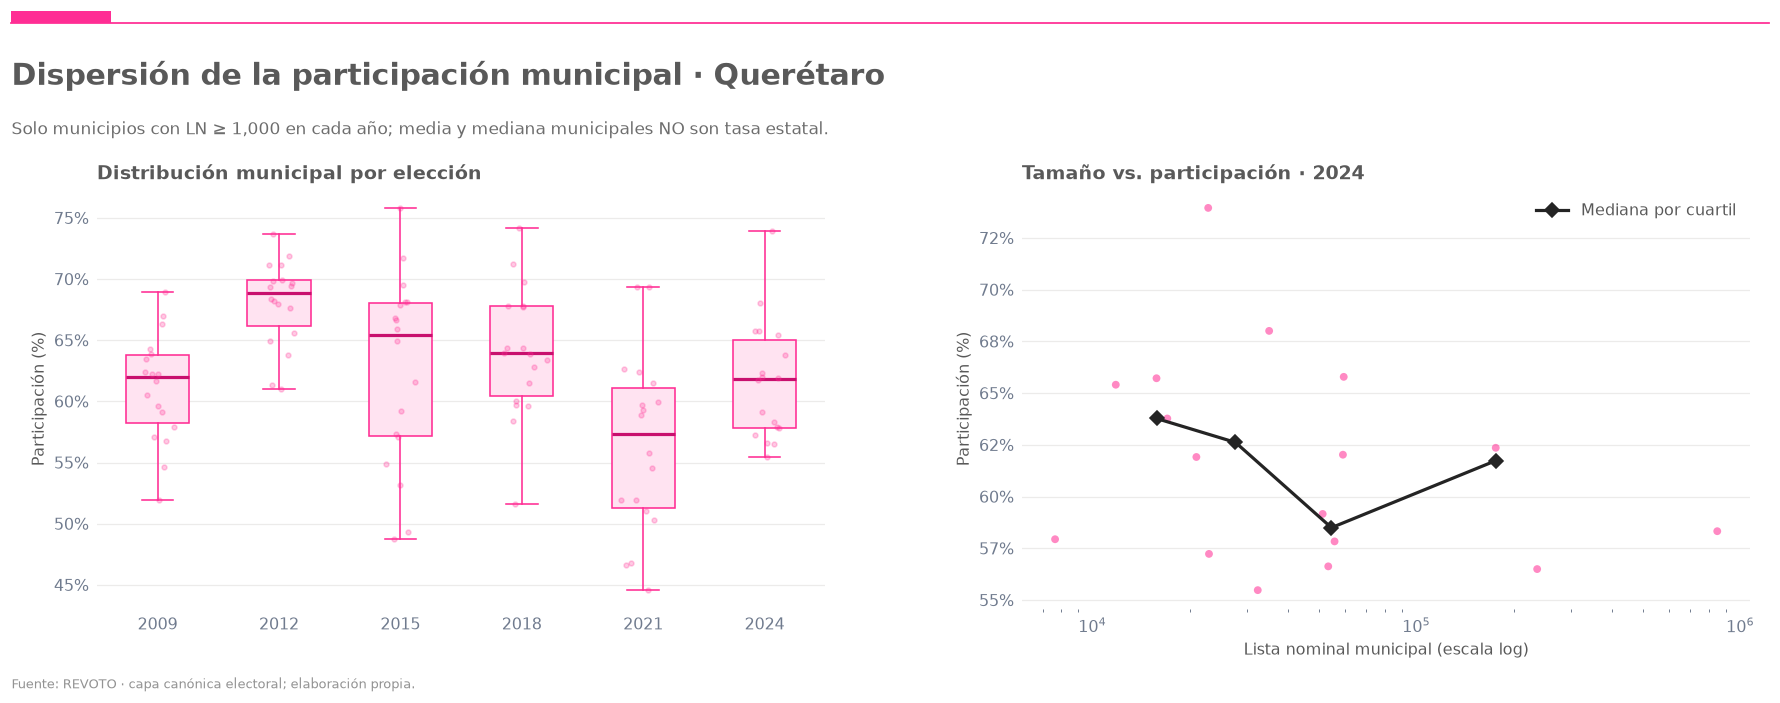

In [60]:
municipal = con.execute('''
    SELECT anio, municipio, SUM(sv) votos, SUM(ln) ln,
           COUNT(DISTINCT seccion) secciones_observadas
    FROM electoral WHERE anio IS NOT NULL AND municipio IS NOT NULL
    GROUP BY 1,2 ORDER BY 1,2
''').fetchdf()
municipal['tasa'] = safe_rate(municipal.votos,municipal.ln)
municipal['municipio_etiqueta'] = municipal.municipio.map(lambda v:f'{int(v):03d}' if pd.notna(v) else 'NA')
mun_vis = municipal[municipal.ln.ge(UMBRAL_LN_EXPLORATORIO) & municipal.tasa.between(0,1)].copy()
print('Municipio–año totales:',len(municipal),'| elegibles para visualización:',len(mun_vis))
resumen_municipal = mun_vis.groupby('anio').agg(municipios=('municipio','nunique'),
             mediana=('tasa','median'), media_no_ponderada=('tasa','mean'),
             min_tasa=('tasa','min'),max_tasa=('tasa','max')).reset_index()
mostrar(resumen_municipal,15)

fig,axs=pagina(f'Dispersión de la participación municipal · {NOMBRE_ESTADO}',
 f'Solo municipios con LN ≥ {UMBRAL_LN_EXPLORATORIO:,} en cada año; media y mediana municipales NO son tasa estatal.'.replace(',',','))
a,b=axs
serie=[100*mun_vis.loc[mun_vis.anio.eq(y),'tasa'].to_numpy() for y in ANIOS_OBSERVADOS]
a.boxplot(serie,positions=np.arange(len(serie)),widths=.52,patch_artist=True,showfliers=False,
          medianprops={'color':VINO_OSCURO,'linewidth':2},
          boxprops={'facecolor':VINO_CLARO,'edgecolor':VINO},
          whiskerprops={'color':VINO},capprops={'color':VINO})
# Muestra determinista, sin saturar si hay cientos de municipios.
rng=np.random.default_rng(33)
for j,v in enumerate(serie):
    if len(v):
        vv=rng.choice(v,min(130,len(v)),replace=False)
        a.scatter(j+rng.normal(0,.07,len(vv)),vv,s=9,alpha=.25,color=VINO,zorder=3)
a.set_xticks(np.arange(len(serie)),ANIOS_OBSERVADOS)
a.set_title('Distribución municipal por elección',loc='left',weight='bold')
a.set_ylabel('Participación (%)'); porciento(a)
ultimo=mun_vis[mun_vis.anio.eq(ANIO_FINAL)].copy()
b.scatter(ultimo.ln,ultimo.tasa*100,s=24,alpha=.56,color=VINO,edgecolor='none')
if not ultimo.empty:
    try:
        ultimo['cuartil']=pd.qcut(ultimo.ln,4,labels=False,duplicates='drop')
        quart=ultimo.groupby('cuartil').agg(x=('ln','median'),y=('tasa','median'))
        b.plot(quart.x,quart.y*100,color='#242424',marker='D',linewidth=2,label='Mediana por cuartil')
        b.legend(frameon=False,loc='best')
    except ValueError:
        pass
b.set_xscale('log');b.set_xlabel('Lista nominal municipal (escala log)')
b.set_title(f'Tamaño vs. participación · {ANIO_FINAL}',loc='left',weight='bold')
b.set_ylabel('Participación (%)');porciento(b)
cerrar(fig,'04_dispersion_municipal')

### 3.1 · Extremos municipales y movilidad en el ranking

Los extremos son de la **submuestra visual elegible**. Se usan claves municipales para no inventar nombres. El coeficiente de Spearman (−1 a +1) mide estabilidad relativa de posiciones: valores cercanos a cero indican poca correspondencia entre rangos, pero requieren revisar empates, cambios de cobertura y comparabilidad histórica.

,anio,municipio,votos,ln,secciones_observadas,tasa,municipio_etiqueta,grupo
107,2024,18,16806.0,22726.0,13,0.739505,018,Mayor
95,2024,6,23835.0,35048.0,17,0.680067,006,Mayor
106,2024,17,39174.0,59548.0,30,0.657856,017,Mayor
101,2024,12,10342.0,15737.0,14,0.657177,012,Mayor
91,2024,2,7706.0,11782.0,11,0.654049,002,Mayor
98,2024,9,10837.0,16993.0,14,0.637733,009,Mayor
99,2024,10,109400.0,175441.0,56,0.623571,010,Mayor
100,2024,11,36725.0,59212.0,25,0.620229,011,Mayor
102,2024,13,12936.0,20894.0,18,0.619125,013,Mayor
94,2024,5,108603.0,175899.0,66,0.617417,005,Mayor


anio,2009,2012,2015,2018,2021,2024
anio,,,,,,
2009,1.00,0.80,0.49,0.62,0.64,0.74
2012,0.80,1.00,0.51,0.75,0.63,0.72
2015,0.49,0.51,1.00,0.66,0.91,0.39
2018,0.62,0.75,0.66,1.00,0.66,0.52
2021,0.64,0.63,0.91,0.66,1.00,0.66
2024,0.74,0.72,0.39,0.52,0.66,1.00


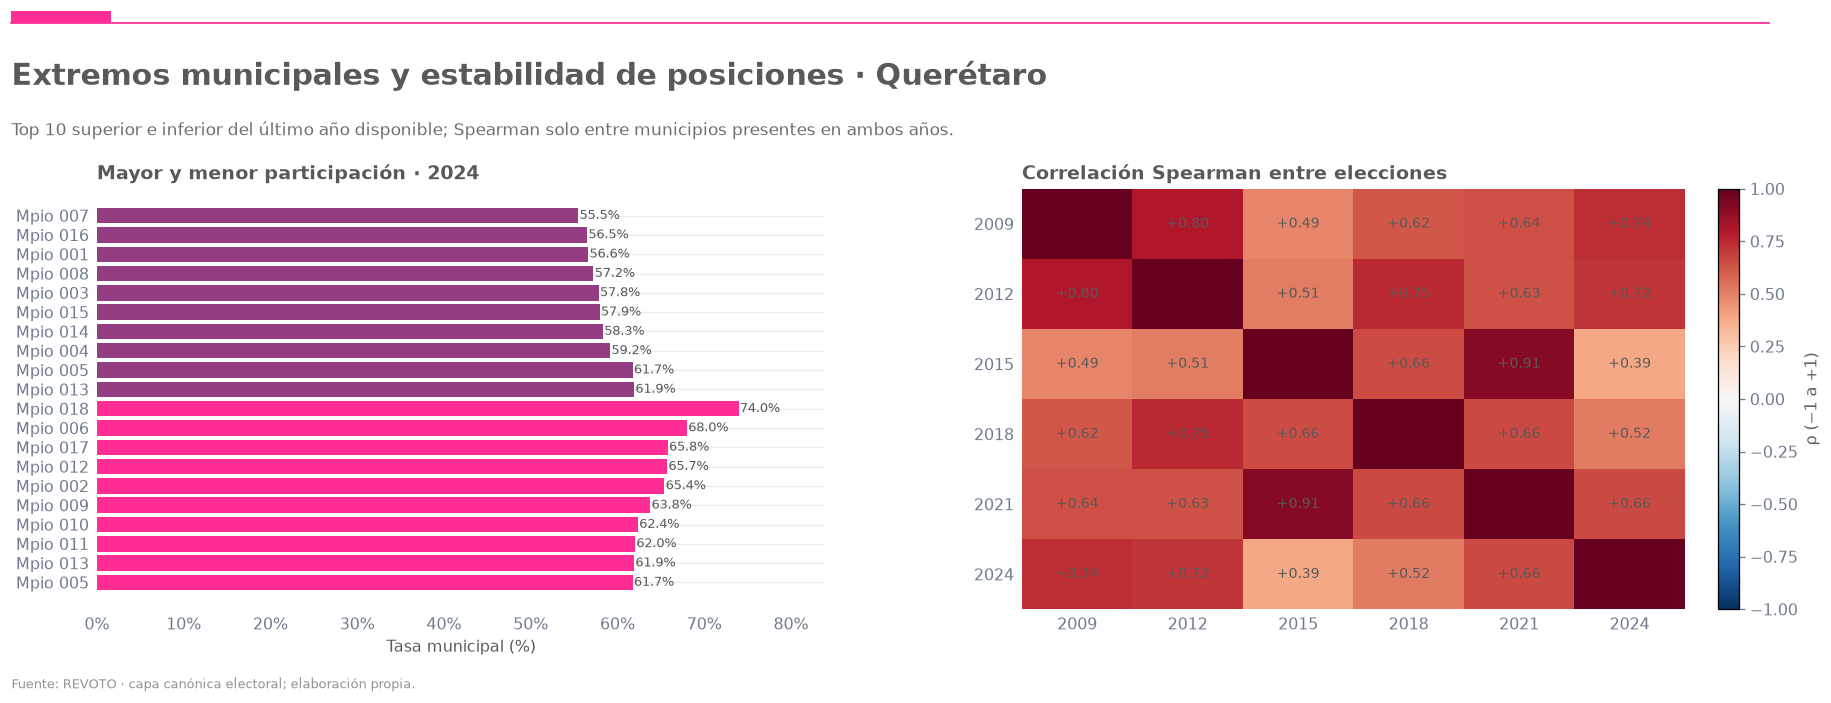

In [61]:
rankings = mun_vis[mun_vis.anio.eq(ANIO_FINAL)].sort_values('tasa').copy()
top_bajos = rankings.head(10)
top_altos = rankings.tail(10).sort_values('tasa',ascending=False)
piv = mun_vis.pivot(index='municipio',columns='anio',values='tasa')
rank_corr = piv.corr(method='spearman',min_periods=3).reindex(index=ANIOS_OBSERVADOS,columns=ANIOS_OBSERVADOS)
pares = piv.notna().astype(int).T.dot(piv.notna().astype(int))
mostrar(pd.concat([top_altos.assign(grupo='Mayor'),top_bajos.assign(grupo='Menor')]))
mostrar(rank_corr.round(2),15)

fig,axs=pagina(f'Extremos municipales y estabilidad de posiciones · {NOMBRE_ESTADO}',
 'Top 10 superior e inferior del último año disponible; Spearman solo entre municipios presentes en ambos años.')
a,b=axs
valores=pd.concat([top_altos.sort_values('tasa',ascending=True),top_bajos.sort_values('tasa',ascending=False)])
colores=[VINO]*len(top_altos)+[AZUL]*len(top_bajos)
a.barh(np.arange(len(valores)),valores.tasa*100,color=colores)
a.set_yticks(np.arange(len(valores)),[f'Mpio {v}' for v in valores.municipio_etiqueta])
a.set_xlabel('Tasa municipal (%)'); porciento(a,eje='x')
a.set_title(f'Mayor y menor participación · {ANIO_FINAL}',loc='left',weight='bold')
for i,v in enumerate(valores.tasa): a.text(v*100+.15,i,f'{v:.1%}',va='center',fontsize=8.2)
a.set_xlim(0,max(100*valores.tasa.max()+10,10) if len(valores) else 100)
mat=rank_corr.to_numpy(dtype=float)
im=b.imshow(np.ma.masked_invalid(mat),cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
b.set_xticks(range(len(ANIOS_OBSERVADOS)),ANIOS_OBSERVADOS)
b.set_yticks(range(len(ANIOS_OBSERVADOS)),ANIOS_OBSERVADOS)
b.grid(False)
for i in range(len(mat)):
    for j in range(len(mat)):
        if i!=j and np.isfinite(mat[i,j]):
            b.text(j,i,f'{mat[i,j]:+.2f}',ha='center',va='center',fontsize=9)
b.set_title('Correlación Spearman entre elecciones',loc='left',weight='bold')
fig.colorbar(im,ax=b,fraction=.045,pad=.045,label='ρ (−1 a +1)')
cerrar(fig,'05_rankings_estabilidad')

### 3.2 · Secciones y códigos distritales (granularidad conservada)

Las secciones se identifican por la **pareja municipio–sección** dentro del estado y elección; la clave `SECCION` sola puede reutilizarse en otros municipios. El distrito `DEL` se representa como **código**, sin asumir equivalencias geográficas entre años. Estos agregados son diagnósticos descriptivos y requieren política RN-05, metadatos y delimitaciones para llegar al frontend.

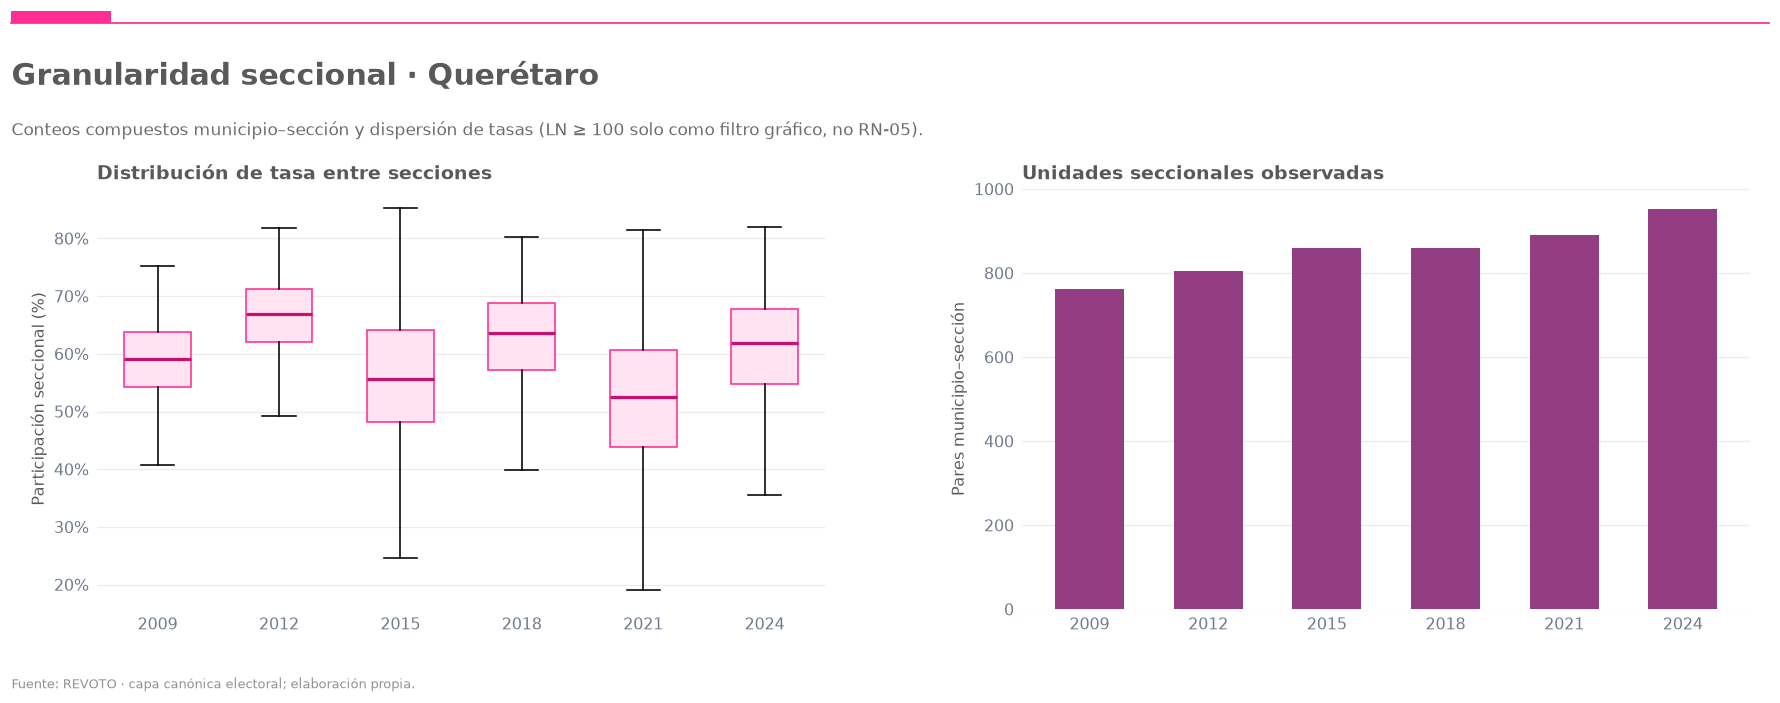

,anio,municipio,seccion,ln,votos,tasa
0,2009,1,1,1040.0,719.0,0.691346
1,2009,1,2,838.0,558.0,0.665871
2,2009,1,3,1289.0,797.0,0.618309
3,2009,1,4,1445.0,877.0,0.606920
4,2009,1,5,1219.0,812.0,0.666120
5,2009,1,6,809.0,448.0,0.553770
6,2009,1,7,563.0,338.0,0.600355
7,2009,1,8,1039.0,567.0,0.545717
8,2009,1,9,1606.0,735.0,0.457659
9,2009,1,10,969.0,529.0,0.545924


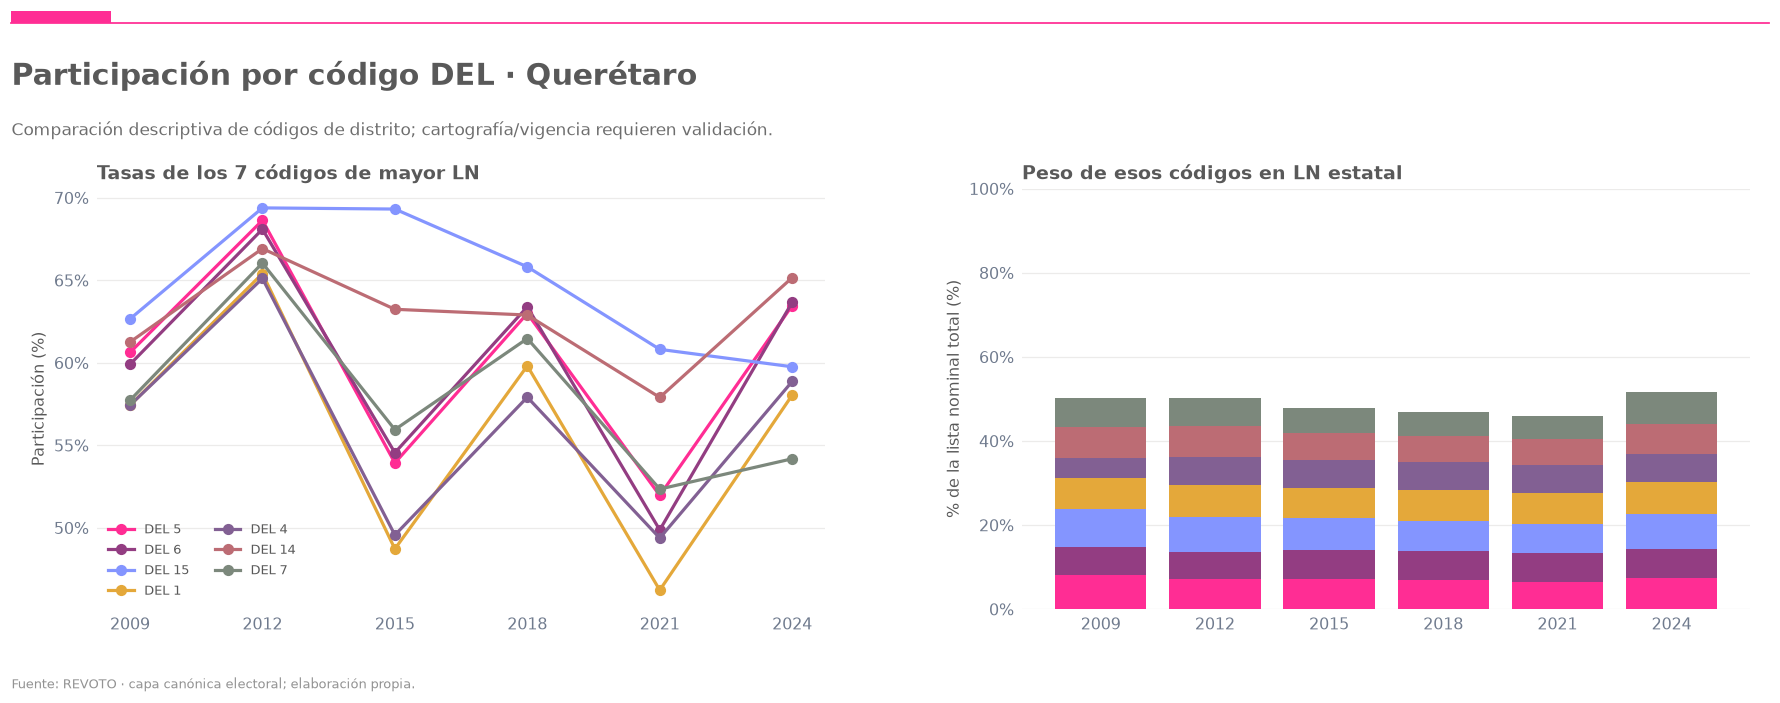

,anio,distrito_local,ln,votos,tasa
0,2009,1,89971.0,51669.0,0.574285
1,2009,2,72147.0,40579.0,0.562449
2,2009,3,57968.0,31987.0,0.551804
3,2009,4,74680.0,42891.0,0.574330
4,2009,5,99271.0,60188.0,0.606300
5,2009,6,80738.0,48372.0,0.599123
6,2009,7,54547.0,31492.0,0.577337
7,2009,8,84778.0,47854.0,0.564462
8,2009,9,61324.0,31205.0,0.508855
9,2009,10,72889.0,42350.0,0.581020


In [62]:
seccional=con.execute('''
    SELECT anio, municipio, seccion, SUM(ln) ln, SUM(sv) votos
    FROM electoral WHERE anio IS NOT NULL AND municipio IS NOT NULL AND seccion IS NOT NULL
    GROUP BY 1,2,3 ORDER BY 1,2,3
''').fetchdf()
seccional['tasa']=safe_rate(seccional.votos,seccional.ln)
seccional_vis=seccional[seccional.ln.ge(100)&seccional.tasa.between(0,1)].copy()
fig,axs=pagina(f'Granularidad seccional · {NOMBRE_ESTADO}',
 'Conteos compuestos municipio–sección y dispersión de tasas (LN ≥ 100 solo como filtro gráfico, no RN-05).')
a,b=axs
vals=[seccional_vis.loc[seccional_vis.anio.eq(y),'tasa'].to_numpy()*100 for y in ANIOS_OBSERVADOS]
a.boxplot([v if len(v) else np.array([np.nan]) for v in vals],
          positions=range(len(vals)),widths=.55,patch_artist=True,showfliers=False,
          boxprops={'facecolor':VINO_CLARO,'edgecolor':VINO},
          medianprops={'color':VINO_OSCURO,'linewidth':2})
a.set_xticks(range(len(vals)),ANIOS_OBSERVADOS)
a.set_title('Distribución de tasa entre secciones',loc='left',weight='bold')
a.set_ylabel('Participación seccional (%)');porciento(a)
b.bar(cobertura.anio.astype(str),cobertura.secciones_municipales,color=AZUL,width=.58)
b.set_title('Unidades seccionales observadas',loc='left',weight='bold')
b.set_ylabel('Pares municipio–sección')
cerrar(fig,'05b_secciones')
mostrar(seccional[['anio','municipio','seccion','ln','votos','tasa']],10)

distrital=pd.DataFrame()
if MAPEO.get('distrito_local'):
    distrital=con.execute('''
        SELECT anio, distrito_local, SUM(ln) ln, SUM(sv) votos
        FROM electoral WHERE anio IS NOT NULL AND distrito_local IS NOT NULL
        GROUP BY 1,2 ORDER BY 1,2
    ''').fetchdf()
    distrital['tasa']=safe_rate(distrital.votos,distrital.ln)
    if not distrital.empty:
        ranking_del=(distrital[distrital.anio.eq(ANIO_FINAL)].nlargest(7,'ln')
                     .distrito_local.tolist())
        fig,axs=pagina(f'Participación por código DEL · {NOMBRE_ESTADO}',
                      'Comparación descriptiva de códigos de distrito; cartografía/vigencia requieren validación.')
        a,b=axs
        for j,cod in enumerate(ranking_del):
            dd=distrital[distrital.distrito_local.eq(cod)]
            a.plot(dd.anio,dd.tasa*100,marker='o',lw=2,color=COLORES[j%len(COLORES)],label=f'DEL {int(cod)}')
        a.set_xticks(ANIOS_OBSERVADOS);a.set_title('Tasas de los 7 códigos de mayor LN',loc='left',weight='bold')
        a.set_ylabel('Participación (%)');porciento(a)
        a.legend(frameon=False,ncol=2,fontsize=8)
        compos=distrital[distrital.distrito_local.isin(ranking_del)].pivot_table(
            index='anio',columns='distrito_local',values='ln',aggfunc='sum',fill_value=0)
        # % respecto a LN TOTAL del estado, no únicamente la selección top 7.
        den=distrital.groupby('anio').ln.sum().reindex(compos.index).replace(0,np.nan)
        compos=compos.div(den,axis=0)*100
        fondo=np.zeros(len(compos))
        for j,cod in enumerate(compos.columns):
            v=compos[cod].to_numpy()
            b.bar(compos.index.astype(str),v,bottom=fondo,color=COLORES[j%len(COLORES)],label=f'DEL {int(cod)}')
            fondo+=v
        b.set_title('Peso de esos códigos en LN estatal',loc='left',weight='bold')
        b.set_ylabel('% de la lista nominal total (%)');porciento(b)
        b.set_ylim(0,100)
        cerrar(fig,'05c_codigos_distritales')
    mostrar(distrital,15)
else:
    nota('El código DEL no está presente en esta fuente; se omite el análisis distrital sin estimar sus valores.')

## 4 · Dimensiones de sexo, sección, edad y cohorte

Cada dimensión incluye **mínimo dos lecturas**: nivel/tendencia de participación y magnitud, composición o brecha. Los grupos solo pueden compararse bajo la misma definición de `SV`, `LN` y año de elección; una composición es un porcentaje de volumen y **no** una tasa de participación.

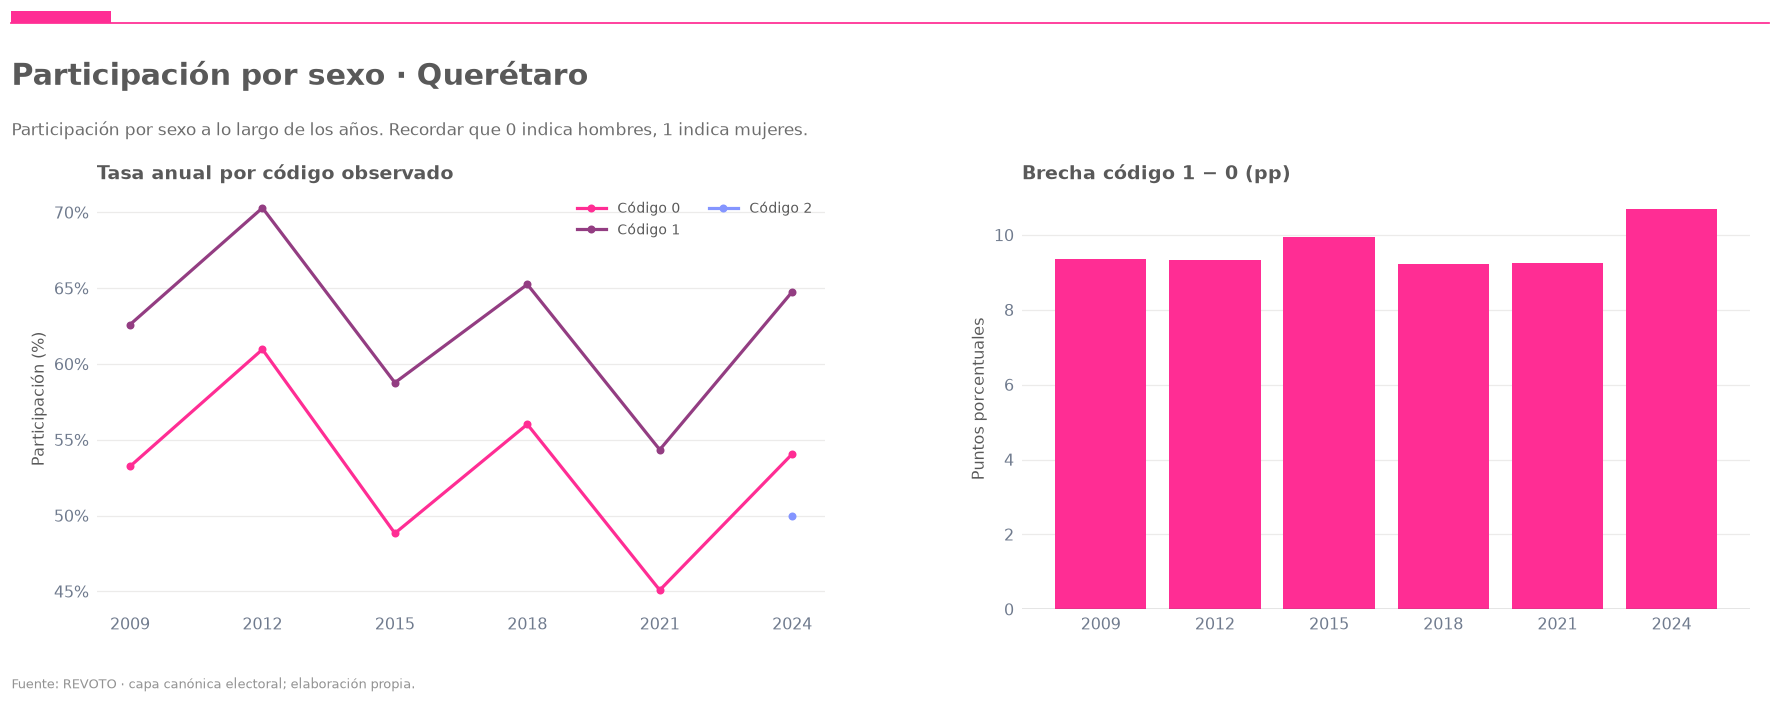

,anio,grupo,votos,lista,tasa
0,2009,0,293760.0,551701.0,0.532462
1,2009,1,377420.0,602892.0,0.626016
2,2012,0,359794.0,590159.0,0.609656
3,2012,1,450859.0,641329.0,0.703007
4,2015,0,331738.0,679335.0,0.488328
5,2015,1,431636.0,734463.0,0.587689
6,2018,0,428097.0,764135.0,0.560237
7,2018,1,534321.0,818823.0,0.652548
8,2021,0,379141.0,840982.0,0.450831
9,2021,1,486633.0,895406.0,0.543477


In [63]:
def agrupar_dimension(dim):
    if not MAPEO.get(dim):
        print(f'Omitido {dim}: no está en el esquema de la fuente.')
        return pd.DataFrame(columns=['anio','grupo','votos','lista','tasa'])
    df=con.execute(f'''
        SELECT anio, CAST({ident(dim)} AS VARCHAR) grupo, SUM(sv) votos, SUM(ln) lista
        FROM electoral WHERE anio IS NOT NULL AND {ident(dim)} IS NOT NULL
        GROUP BY 1,2 ORDER BY 1,2
    ''').fetchdf()
    df['tasa'] = safe_rate(df.votos,df.lista)
    return df

def composicion_pivot(df,valor='lista'):
    p=df.pivot_table(index='anio',columns='grupo',values=valor,aggfunc='sum',fill_value=0)
    return p.div(p.sum(axis=1).replace(0,np.nan),axis=0)*100

def lineas_dimension(ax,df,labels=None,orden=None):
    grupos=orden or df.grupo.dropna().unique().tolist()
    for idx,g in enumerate(grupos):
        a=df[df.grupo.eq(g)].sort_values('anio')
        if a.empty: continue
        nombre = labels.get(str(g),f'Código {g}') if labels else f'Código {g}'
        ax.plot(a.anio,a.tasa*100,marker='o',markersize=4,linewidth=2,
                color=COLORES[idx%len(COLORES)],label=nombre)
    ax.set_xticks(ANIOS_OBSERVADOS)
    ax.set_ylabel('Participación (%)');porciento(ax)
    ax.legend(frameon=False,ncol=2,fontsize=9,loc='best')

sexo_df=agrupar_dimension('sexo')
if len(sexo_df):
    ultimo_sexo=sexo_df[sexo_df.anio.eq(ANIO_FINAL)].sort_values('lista',ascending=False)
    codigos=ultimo_sexo.grupo.head(2).tolist()
    fig,axs=pagina(f'Participación por sexo · {NOMBRE_ESTADO}',
        'Participación por sexo a lo largo de los años. Recordar que 0 indica hombres, 1 indica mujeres.')
    a,b=axs
    lineas_dimension(a,sexo_df,ETIQUETAS_SEXO)
    a.set_title('Tasa anual por código observado',loc='left',weight='bold')
    if len(codigos)==2:
        pp=sexo_df.pivot(index='anio',columns='grupo',values='tasa')
        brecha=(pp[codigos[0]]-pp[codigos[1]])*100
        b.bar(brecha.index.astype(str),brecha,color=[VINO if x>=0 else AZUL for x in brecha])
        b.axhline(0,color=GRIS,lw=.8)
        b.set_title(f'Brecha código {codigos[0]} − {codigos[1]} (pp)',loc='left',weight='bold')
        b.set_ylabel('Puntos porcentuales')
    else:
        b.text(.05,.5,'No hay dos códigos comparables',transform=b.transAxes)
    cerrar(fig,'06_participacion_sexo')
    mostrar(sexo_df)

### 4.1 · Tipo de sección

`TIPOSEC` se conserva en códigos sin convertir por defecto 1/2/3 en etiquetas urbano/rural/mixto. La composición de la lista nominal expresa **peso relativo**, no participación. Los nombres pueden habilitarse únicamente tras comprobar el diccionario de INE.

In [64]:
tipo_df=agrupar_dimension('tiposec')
if len(tipo_df):
    fig,axs=pagina('Participación por tipo de sección',
        'Tasa por categoría y composición de LN; significados de TIPOSEC pendientes de diccionario.')
    a,b=axs
    lineas_dimension(a,tipo_df,ETIQUETAS_TIPOSEC)
    a.set_title('Tasa por categoría',loc='left',weight='bold')
    shares=composicion_pivot(tipo_df)
    base=np.zeros(len(shares))
    for j,g in enumerate(shares.columns):
        vals=shares[g].to_numpy()
        b.bar(shares.index.astype(str),vals,bottom=base,color=COLORES[j%len(COLORES)],
              label=ETIQUETAS_TIPOSEC.get(str(g),f'TIPOSEC {g}'),width=.63)
        base+=vals
    b.set_ylim(0,100); b.set_ylabel('Porcentaje de la LN (%)');porciento(b)
    b.set_title('Composición de la lista nominal',loc='left',weight='bold')
    b.legend(frameon=False,fontsize=9,ncol=2)
    cerrar(fig,'07_tipos_seccion')
    mostrar(tipo_df)

### 4.2 · Perfil de participación por edad

En lugar de una línea por cada edad (ilegible), se trazan **líneas de edad para cada elección** y, para la última elección, la distribución relativa de la lista nominal y de los votos. Las categorías de edad no numéricas o desconocidas permanecen en la auditoría, pero no se ordenan como edades continuas.

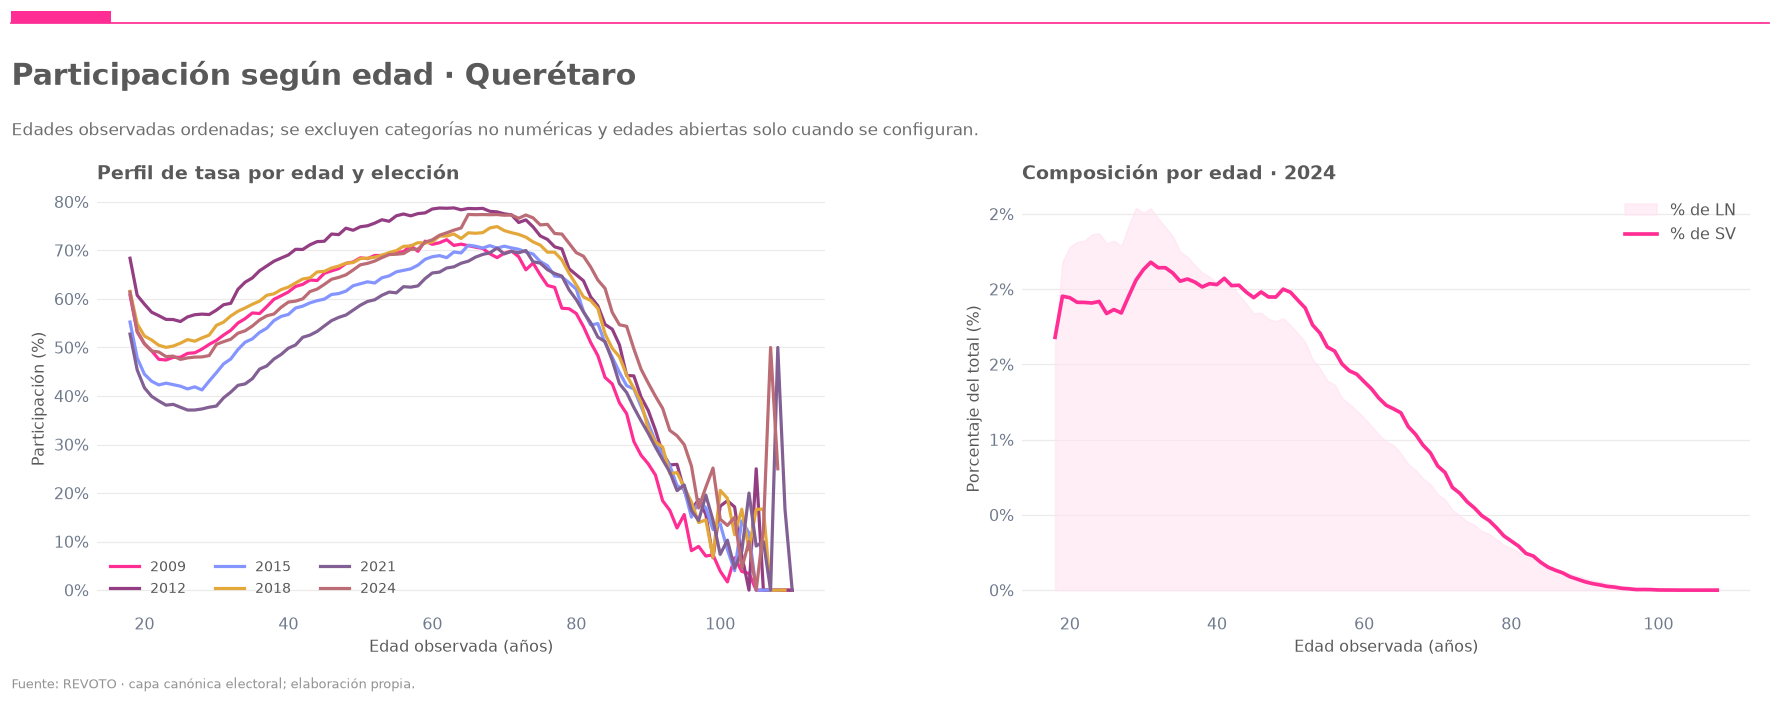

,anio,edad_num,lista,votos,tasa
563,2024,94,723.0,230.0,0.318119
564,2024,95,467.0,140.0,0.299786
565,2024,96,387.0,99.0,0.255814
566,2024,97,260.0,44.0,0.169231
567,2024,98,231.0,49.0,0.212121
568,2024,99,159.0,40.0,0.251572
477,2024,100,89.0,13.0,0.146067
478,2024,101,60.0,8.0,0.133333
479,2024,102,40.0,6.0,0.150000
480,2024,103,22.0,1.0,0.045455


In [65]:
edad_df=agrupar_dimension('edad')
if len(edad_df):
    edad_df['edad_num'] = pd.to_numeric(edad_df.grupo,errors='coerce')
    edades = edad_df[edad_df.edad_num.between(18,110)].sort_values(['anio','edad_num']).copy()
    if EDAD_TOPE_ABIERTA is not None:
        edades=edades[edades.edad_num.lt(EDAD_TOPE_ABIERTA)].copy()
    fig,axs=pagina(f'Participación según edad · {NOMBRE_ESTADO}',
       'Edades observadas ordenadas; se excluyen categorías no numéricas y edades abiertas solo cuando se configuran.')
    a,b=axs
    for j,(anio,grp) in enumerate(edades.groupby('anio')):
        a.plot(grp.edad_num,grp.tasa*100,color=COLORES[j%len(COLORES)],
               linewidth=2,label=str(int(anio)))
    a.set_title('Perfil de tasa por edad y elección',loc='left',weight='bold')
    a.set_xlabel('Edad observada (años)');a.set_ylabel('Participación (%)');porciento(a)
    a.legend(frameon=False,ncol=3,fontsize=9)
    ult=edades[edades.anio.eq(ANIO_FINAL)].copy()
    if not ult.empty:
        ult['share_ln']=100*ult.lista/ult.lista.sum()
        ult['share_sv']=100*ult.votos/ult.votos.sum()
        b.fill_between(ult.edad_num,ult.share_ln,alpha=.6,color=VINO_CLARO,label='% de LN')
        b.plot(ult.edad_num,ult.share_sv,color=VINO,lw=2.3,label='% de SV')
    b.set_xlabel('Edad observada (años)'); b.set_ylabel('Porcentaje del total (%)');porciento(b)
    b.set_title(f'Composición por edad · {ANIO_FINAL}',loc='left',weight='bold')
    b.legend(frameon=False)
    cerrar(fig,'08_edad')
    mostrar(edades[['anio','edad_num','lista','votos','tasa']].tail(15))

### 4.3 · Cohortes de nacimiento aproximadas

Se aproxima `año_nacimiento = año_electoral − edad` y se agrupan edades en generaciones convencionales. Puede haber un desfase de un año según fecha de nacimiento. **No** es un panel longitudinal de personas: cada año observa un conjunto distinto de electores. Si existe categoría superior abierta (p. ej. «90 y más»), configura `EDAD_TOPE_ABIERTA` tras verificar su semántica para excluirla de este cálculo.

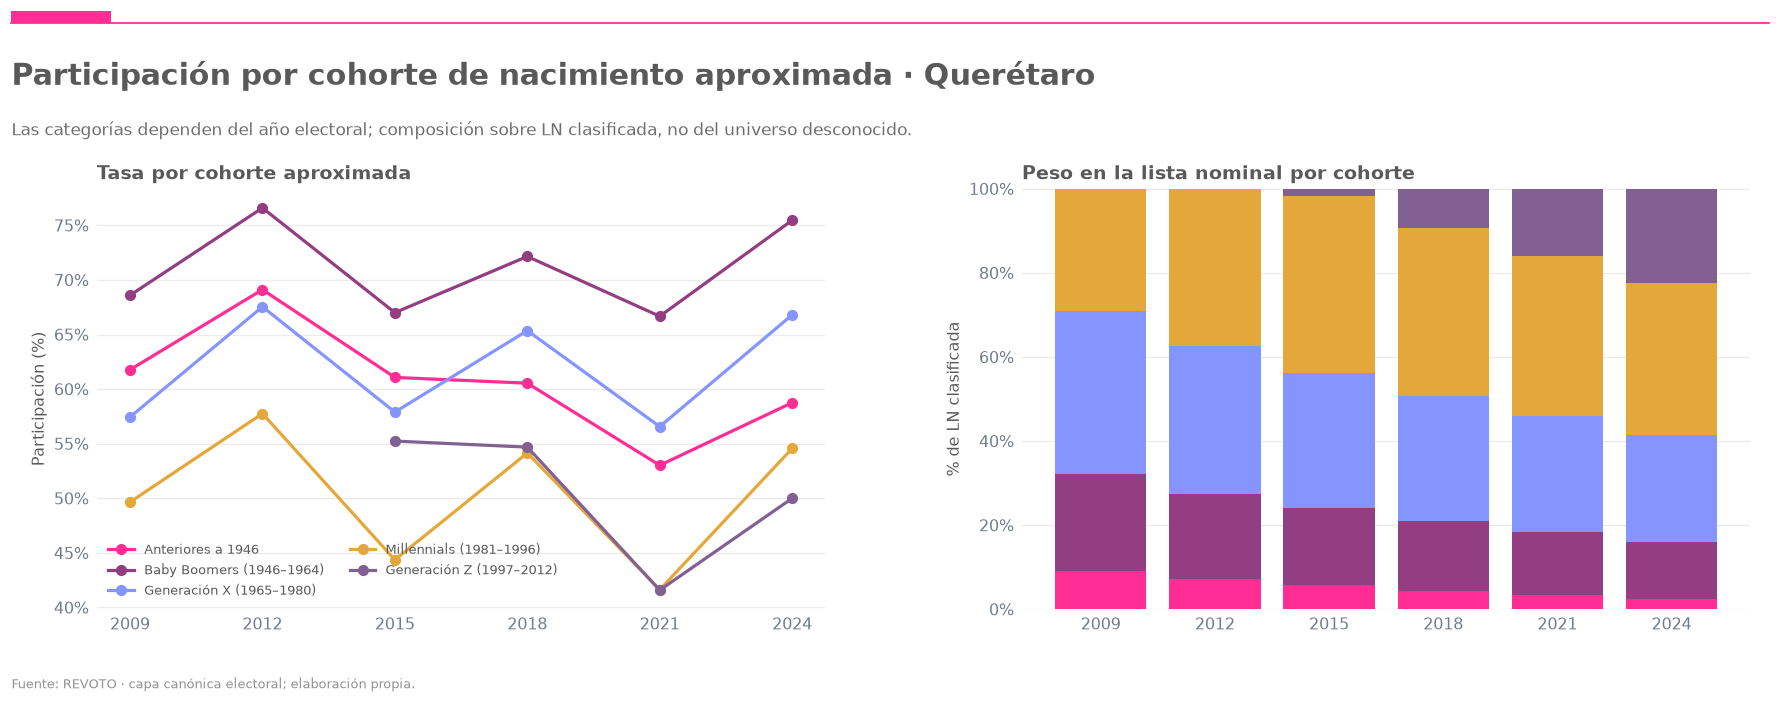

,anio,cohorte,lista,votos,tasa
0,2009,Anteriores a 1946,105847.0,65388.0,0.617760
1,2009,Baby Boomers (1946–1964),265320.0,182003.0,0.685975
2,2009,Generación X (1965–1980),446597.0,256539.0,0.574431
3,2009,Millennials (1981–1996),336817.0,167246.0,0.496549
4,2012,Anteriores a 1946,87447.0,60438.0,0.691139
5,2012,Baby Boomers (1946–1964),250072.0,191561.0,0.766023
6,2012,Generación X (1965–1980),432325.0,292008.0,0.675436
7,2012,Millennials (1981–1996),461642.0,266645.0,0.577601
8,2015,Anteriores a 1946,80879.0,49396.0,0.610739
9,2015,Baby Boomers (1946–1964),259623.0,173964.0,0.670064


In [66]:
COHORTES = ['Anteriores a 1946','Baby Boomers (1946–1964)','Generación X (1965–1980)',
            'Millennials (1981–1996)','Generación Z (1997–2012)','Posteriores a 2012']
def cohorte(nacimiento):
    if pd.isna(nacimiento): return None
    n=int(nacimiento)
    if n<1946:return COHORTES[0]
    if n<=1964:return COHORTES[1]
    if n<=1980:return COHORTES[2]
    if n<=1996:return COHORTES[3]
    if n<=2012:return COHORTES[4]
    return COHORTES[5]

cohortes=pd.DataFrame()
if len(edad_df):
    cohortes=edades.copy()
    cohortes['nacimiento_aprox']=cohortes.anio-cohortes.edad_num
    cohortes['cohorte']=cohortes.nacimiento_aprox.map(cohorte)
    cohortes=cohortes.groupby(['anio','cohorte'],as_index=False)[['lista','votos']].sum()
    cohortes['tasa']=safe_rate(cohortes.votos,cohortes.lista)
    fig,axs=pagina(F'Participación por cohorte de nacimiento aproximada · {NOMBRE_ESTADO}',
        'Las categorías dependen del año electoral; composición sobre LN clasificada, no del universo desconocido.')
    a,b=axs
    orden=[k for k in COHORTES if k in set(cohortes.cohorte)]
    for j,k in enumerate(orden):
        grp=cohortes[cohortes.cohorte.eq(k)]
        a.plot(grp.anio,grp.tasa*100,marker='o',lw=2,color=COLORES[j%len(COLORES)],label=k)
    a.set_xticks(ANIOS_OBSERVADOS);a.set_ylabel('Participación (%)');porciento(a)
    a.set_title('Tasa por cohorte aproximada',loc='left',weight='bold')
    a.legend(frameon=False,fontsize=8,ncol=2,loc='best')
    wide=cohortes.pivot_table(index='anio',columns='cohorte',values='lista',fill_value=0)
    wide=wide.div(wide.sum(axis=1).replace(0,np.nan),axis=0)*100
    fondo=np.zeros(len(wide))
    for j,k in enumerate(orden):
        vals=wide[k].to_numpy() if k in wide else np.zeros(len(wide))
        b.bar(wide.index.astype(str),vals,bottom=fondo,color=COLORES[j%len(COLORES)],label=k)
        fondo+=vals
    b.set_ylim(0,100);b.set_ylabel('% de LN clasificada');porciento(b)
    b.set_title('Peso en la lista nominal por cohorte',loc='left',weight='bold')
    cerrar(fig,'09_cohortes')
    mostrar(cohortes,20)

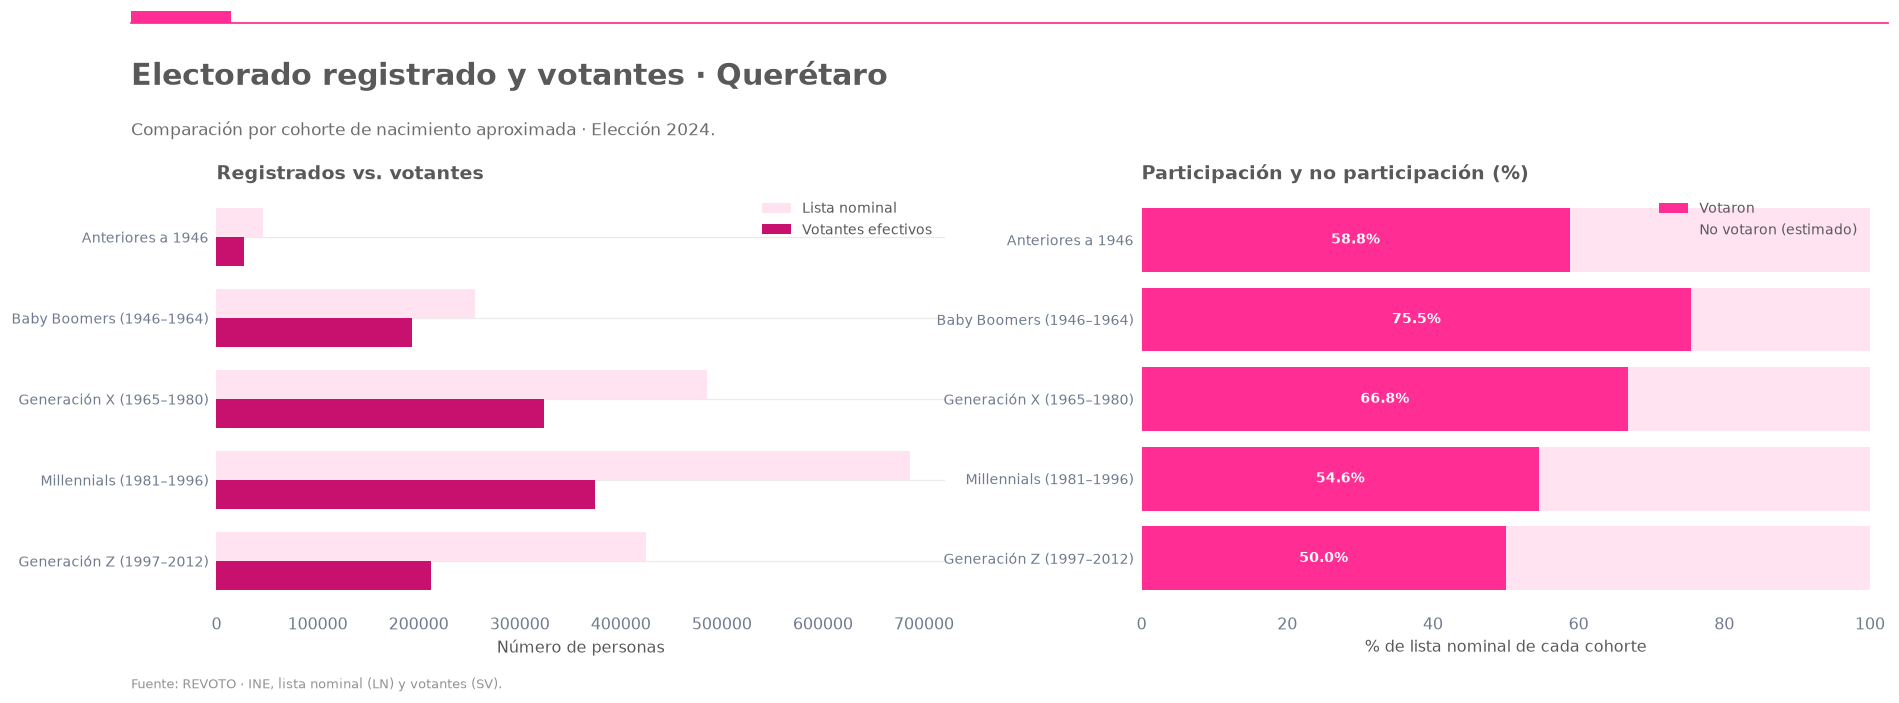

,cohorte,lista,votos,no_votaron,tasa
23,Anteriores a 1946,46467.0,27304.0,19163.0,0.587600
24,Baby Boomers (1946–1964),255733.0,193004.0,62729.0,0.754709
25,Generación X (1965–1980),485499.0,324351.0,161148.0,0.668078
27,Millennials (1981–1996),686358.0,374542.0,311816.0,0.545695
26,Generación Z (1997–2012),424993.0,212507.0,212486.0,0.500025


In [67]:

# ---------------------------------------------------------
# 09B · Lista nominal vs. votantes por cohorte
# ---------------------------------------------------------

cohortes_ultimo = (cohortes.loc[cohortes.anio.eq(ANIO_FINAL)].copy())
cohortes_ultimo['cohorte'] = pd.Categorical(cohortes_ultimo['cohorte'], categories=COHORTES, ordered=True)

cohortes_ultimo = cohortes_ultimo.sort_values('cohorte')
cohortes_ultimo['no_votaron'] = (cohortes_ultimo['lista'] - cohortes_ultimo['votos'])

cohortes_ultimo = cohortes_ultimo.loc[cohortes_ultimo['lista'].gt(0)
                                      & cohortes_ultimo['votos'].ge(0)
                                      & cohortes_ultimo['no_votaron'].ge(0)].copy()

if not cohortes_ultimo.empty:
    fig, axs = pagina(f'Electorado registrado y votantes · {NOMBRE_ESTADO}',
                      f'Comparación por cohorte de nacimiento aproximada · Elección {ANIO_FINAL}.',
                      fuente='REVOTO · INE, lista nominal (LN) y votantes (SV).')
    a, b = axs
    y = np.arange(len(cohortes_ultimo))
    altura = .36

    # Gráfica A: volúmenes absolutos
    a.barh(y - altura / 2, cohortes_ultimo['lista'], height=altura, color=VINO_CLARO, label='Lista nominal')

    a.barh(y + altura / 2, cohortes_ultimo['votos'], height=altura, color=VINO_OSCURO, label='Votantes efectivos')

    a.set_yticks(y)
    a.set_yticklabels(cohortes_ultimo['cohorte'], fontsize=9)
    a.invert_yaxis()
    a.set_xlabel('Número de personas')
    a.set_title('Registrados vs. votantes', loc='left', weight='bold')
    a.legend(frameon=False, fontsize=9)

    # Gráfica B: proporción dentro de cada cohorte
    tasas = cohortes_ultimo['tasa'].to_numpy() * 100
    no_participacion = 100 - tasas

    b.barh(y, tasas, color=VINO, label='Votaron')
    b.barh(y, no_participacion, left=tasas, color=VINO_CLARO, label='No votaron (estimado)')

    for i, valor in enumerate(tasas):
        b.text(valor / 2, i, f'{valor:.1f}%', ha='center', va='center', color='white', weight='bold', fontsize=9)

    b.set_yticks(y)
    b.set_yticklabels(cohortes_ultimo['cohorte'], fontsize=9)
    b.invert_yaxis()
    b.set_xlim(0, 100)
    b.set_xlabel('% de lista nominal de cada cohorte')
    b.set_title('Participación y no participación (%)', loc='left', weight='bold')
    b.legend(frameon=False, fontsize=9)

    cerrar(fig, '09b_cohortes_registrados_vs_votantes')

    mostrar(cohortes_ultimo[['cohorte', 'lista', 'votos', 'no_votaron', 'tasa']], 20)
else:
    nota('No existen cohortes válidas para la comparación.')


## 5 · Geografía: coropletas reales y control de cobertura

Solo se dibujan mapas a partir de **geometrías reales** de la cartografía suministrada. No se sustituyen municipios por cuadros, cuadrículas simuladas o ubicaciones inventadas. Las claves de municipio se normalizan como `entidad (2 dígitos) + municipio (3 dígitos)`; una unión *many-to-many* se rechaza para prevenir duplicación silenciosa. Debe documentarse la **vigencia de cartografía** antes de interpretar cambios históricos.

,cartografia_disponible,n_poligonos,n_con_dato,anio,referencia_cartografica,n_con_cambio
0,True,18,18,2024,None,18


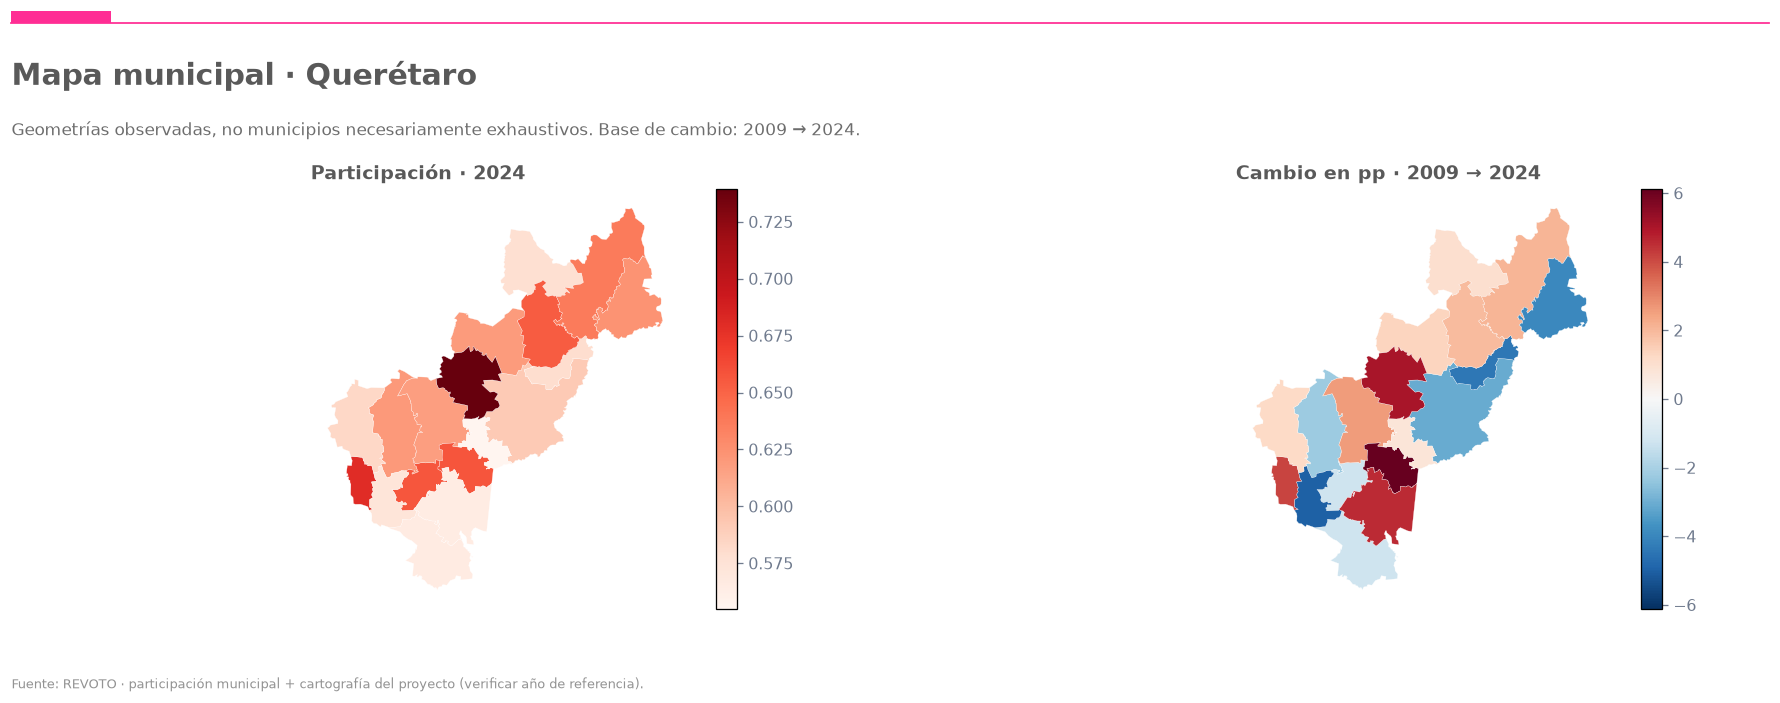

In [68]:
def clave_municipal(serie,cve=CLAVE_ESTADO):
    valores=pd.to_numeric(serie,errors='coerce').astype('Int64')
    return valores.map(lambda v:f'{cve:02d}{int(v):03d}' if pd.notna(v) and 0<=int(v)<=999 else None)

def clave_cvegeo(serie):
    """Normaliza claves municipales de 5 dígitos o claves
    de 9 dígitos con sufijo municipal 0000.
    """
    valores = (serie.astype('string').str.strip().str.replace(r'\.0$', '', regex=True))
    resultado = pd.Series(pd.NA, index=serie.index, dtype='string')
    municipal = valores.str.fullmatch(r'\d{5}').fillna(False)
    localidad_total = valores.str.fullmatch(r'\d{5}0000').fillna(False)
    resultado.loc[municipal] = valores.loc[municipal]
    resultado.loc[localidad_total] = (valores.loc[localidad_total].str[:5])

    return resultado

GEOMETRIA = RAIZ/PATRON_GEOMETRIA.format(edo=EDO)
MAPA_ANIO=ANIO_MAPA if ANIO_MAPA in ANIOS_OBSERVADOS else ANIO_FINAL
mapa_info={'cartografia_disponible':False,'n_poligonos':0,'n_con_dato':0,
           'anio':MAPA_ANIO,'referencia_cartografica':ANIO_REFERENCIA_GEOMETRIA}
mapa_gdf=None
if gpd is None:
    print('Coropletas omitidas: instala geopandas y shapely para habilitarlas.')
elif not GEOMETRIA.is_file():
    print(f'Coropletas omitidas: no existe {GEOMETRIA}')
else:
    try:
        geo=gpd.read_file(GEOMETRIA)
        opciones=[c for c in ('cvegeo','CVEGEO','CVEGEO_MUN','cvegeo_municipal','cve_mun') if c in geo.columns]
        if not opciones:
            print('Sin columna cvegeo verificable en geometría:',geo.columns.tolist())
        elif geo.crs is None:
            print('No se graficó: la capa no declara CRS; corrige su metadato en origen.')
        else:
            geo=geo.copy()
            geo['_join_key']=clave_cvegeo(geo[opciones[0]])
            geo=geo.dropna(subset=['_join_key'])
            duplicadas=geo._join_key.duplicated().sum()
            if duplicadas:
                print(f'{duplicadas} fragmentos de geometrías duplicadas; disolviendo por clave para evitar joins many-to-many.')
                geo=geo.dissolve(by='_join_key',as_index=False)
            el=municipal[municipal.anio.eq(MAPA_ANIO)].copy()
            el['_join_key']=clave_municipal(el.municipio)
            if el._join_key.duplicated().any():
                raise ValueError('La tabla electoral no es única por clave municipal. Revisar agregado.')
            mapa_gdf=geo.merge(el[['_join_key','tasa','ln','votos']],on='_join_key',how='left',validate='one_to_one')
            inicial=municipal[municipal.anio.eq(min(ANIOS_OBSERVADOS))][['municipio','tasa']].copy()
            inicial['_join_key']=clave_municipal(inicial.municipio)
            mapa_gdf=mapa_gdf.merge(inicial[['_join_key','tasa']].rename(columns={'tasa':'tasa_inicial'}),
                                    on='_join_key',how='left',validate='one_to_one')
            mapa_gdf['cambio_pp']=(mapa_gdf.tasa-mapa_gdf.tasa_inicial)*100
            mapa_info.update({'cartografia_disponible':True,'n_poligonos':len(mapa_gdf),
                              'n_con_dato':int(mapa_gdf.tasa.notna().sum()),
                              'n_con_cambio':int(mapa_gdf.cambio_pp.notna().sum())})
            display(pd.DataFrame([mapa_info]))
    except Exception as error:
        print(f'Mapa no disponible: {type(error).__name__}: {error}')
        mapa_gdf=None

if mapa_gdf is not None:
    fig,axs=pagina(f'Mapa municipal · {NOMBRE_ESTADO}',
       f'Geometrías observadas, no municipios necesariamente exhaustivos. Base de cambio: {min(ANIOS_OBSERVADOS)} → {MAPA_ANIO}.',
       fuente='REVOTO · participación municipal + cartografía del proyecto (verificar año de referencia).')
    a,b=axs
    mapa_gdf.plot(ax=a,column='tasa',cmap='Reds',legend=True,edgecolor='white',linewidth=.18,
                  missing_kwds={'color':'#E9E9E9','label':'Sin dato'})
    a.set_axis_off();a.set_title(f'Participación · {MAPA_ANIO}',loc='left',weight='bold')
    limite=np.nanmax(np.abs(mapa_gdf.cambio_pp.to_numpy())) if mapa_gdf.cambio_pp.notna().any() else 1
    if not np.isfinite(limite) or limite==0: limite=1
    mapa_gdf.plot(ax=b,column='cambio_pp',cmap='RdBu_r',
                  norm=TwoSlopeNorm(vmin=-limite,vcenter=0,vmax=limite),legend=True,
                  edgecolor='white',linewidth=.18,
                  missing_kwds={'color':'#E9E9E9','label':'Sin dato'})
    b.set_axis_off();b.set_title(f'Cambio en pp · {min(ANIOS_OBSERVADOS)} → {MAPA_ANIO}',loc='left',weight='bold')
    cerrar(fig,'10_mapas_municipales')
else:
    nota('Sin geometría válida se omiten las coropletas; el notebook **no fabrica un mapa sustituto**. Comprueba ruta, CRS, vigencia y llave cvegeo.')

## 6 · Contexto municipal INEGI y CONAPO

Se usa la capa `full_context` **solo si existe y tiene una llave municipal única por año**. La unión es municipal y **no** desagrega población por sección ni sustituye `LN`. `censo_ref` y `conapo_ref` se reportan por separado. La asociación de Spearman es una descripción **ecológica**: no permite inferir las motivaciones de personas individuales ni relaciones causales. Los registros sin llave, indicadores o correspondencia se contabilizan.

Unión 1:1 por municipio: 18/18 encontrados; llave cvegeo_municipal_inegi.


,censo_ref,conapo_ref,granularidad_contexto,anio_cartografia_referencia,referencia_retroactiva
0,2020,2024,municipio,2023,False


,indicador,n_pares,rho_spearman,anio_eleccion
0,inegi_pobtot,18,0.03612,2024
1,poblacion_conapo,18,0.02580,2024


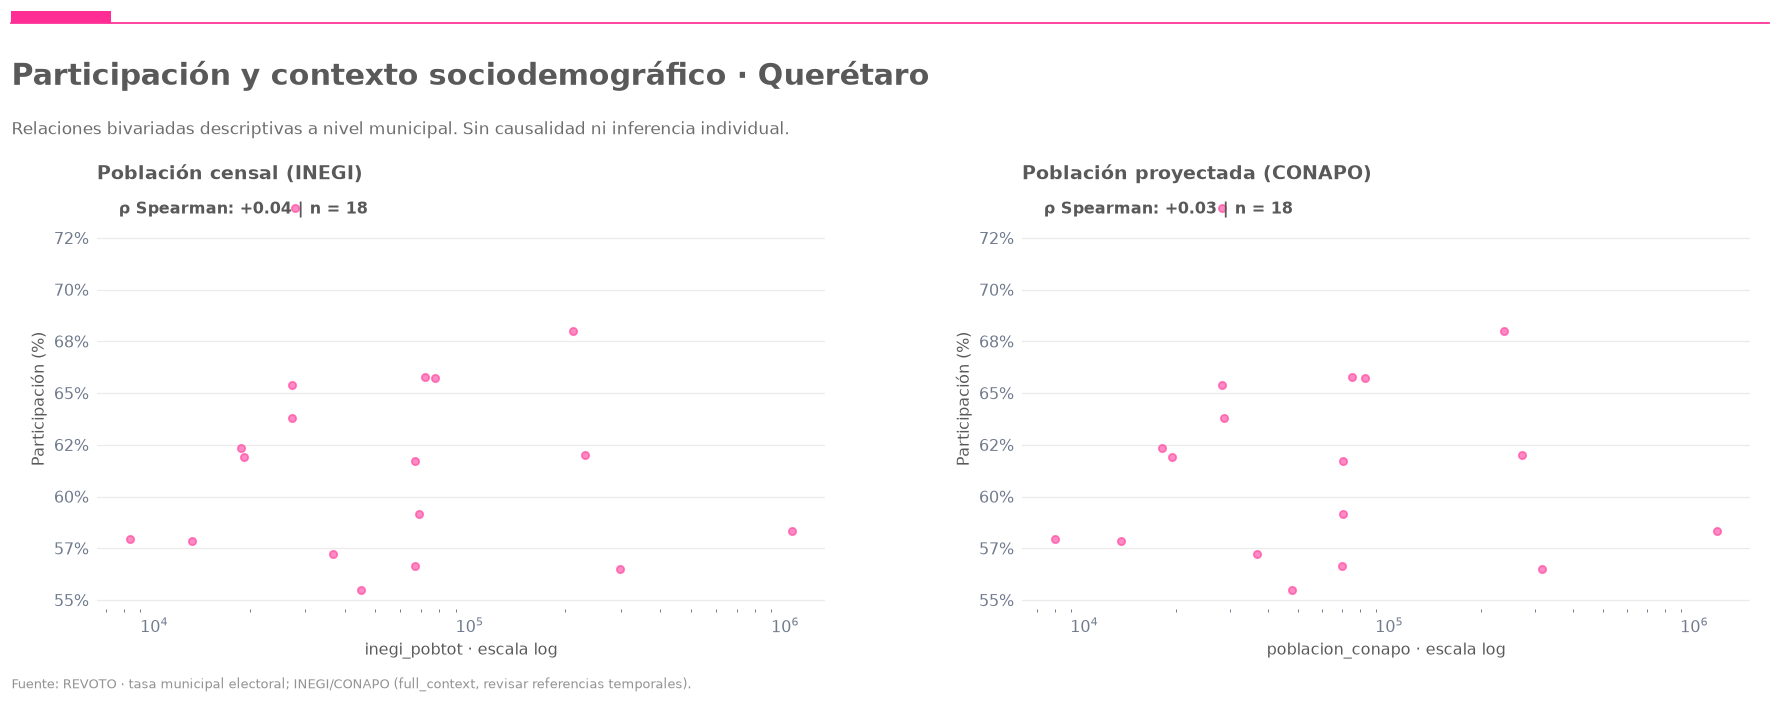

In [69]:
PATRON_CTX = str(RAIZ/PATRON_CONTEXTO.format(edo=EDO))
ARCHIVOS_CONTEXTO=sorted(glob.glob(PATRON_CTX))
contexto_summary=pd.DataFrame()
contexto_pares={}
contexto_estado={'disponible':False,'n_unidos':0,'duplicados':None,'llave':None,'anio':ANIO_FINAL}

if not ARCHIVOS_CONTEXTO:
    print(f'Contexto opcional no disponible. Buscado: {PATRON_CTX}')
else:
    ctx_sql='read_parquet(['+','.join(lit(p) for p in ARCHIVOS_CONTEXTO)+'], union_by_name=true, hive_partitioning=false)'
    ctx_cols=set(con.execute(f'DESCRIBE SELECT * FROM {ctx_sql}').fetchdf().column_name)
    anio_col=next((c for c in ['AELEC','ALEC','anio','anio_eleccion'] if c in ctx_cols),None)
    key_col=next((c for c in ['cvegeo_municipal_inegi','cvegeo','CVEGEO','MPIOCVE'] if c in ctx_cols),None)
    indicators=[c for c in ['inegi_pobtot','poblacion_conapo'] if c in ctx_cols]
    if not anio_col or not key_col or not indicators:
        print('Contexto requiere año, llave única e indicador(es). Columnas observadas:',sorted(ctx_cols))
    else:
        opcionales=[c for c in ['censo_ref','conapo_ref','granularidad_contexto',
                                 'anio_cartografia_referencia','referencia_retroactiva',
                                 'publication_status','inegi_matched','conapo_matched'] if c in ctx_cols]
        cols=[anio_col,key_col,*indicators,*opcionales]
        select=', '.join(ident(c) for c in cols)
        ctx=con.execute(f'SELECT {select} FROM {ctx_sql} WHERE TRY_CAST({ident(anio_col)} AS INT)=?',
                        [ANIO_FINAL]).fetchdf()
        ctx['_join_key']=(clave_municipal(ctx[key_col]) if key_col=='MPIOCVE'
                          else clave_cvegeo(ctx[key_col]))
        contexto_estado['llave']=key_col
        contexto_estado['duplicados']=int(ctx.loc[ctx._join_key.notna(),'_join_key'].duplicated().sum())
        if contexto_estado['duplicados']:
            print('Asociaciones omitidas: llave duplicada en contexto. Revisar particiones/crosswalk:',
                  contexto_estado['duplicados'])
        elif ctx.empty:
            print(f'Contexto sin registros de {ANIO_FINAL}.')
        else:
            el=municipal[municipal.anio.eq(ANIO_FINAL)].copy()

            """ Mini-Diagnóstico de llaves municipales INE × INEGI/CONAPO
            el_test = municipal.loc[municipal['anio'].eq(ANIO_FINAL)].copy()
            el_test['_join_key'] = clave_municipal(el_test['municipio'])
            ctx_test = ctx.copy()

            ine_keys = set(el_test['_join_key'].dropna())
            ctx_keys = set(ctx_test['_join_key'].dropna())

            print(f'Estado: {NOMBRE_ESTADO} ({EDO})')
            print(f'Año: {ANIO_FINAL}')
            print(f'Columna contexto: {key_col}')
            print(f'Municipios electorales: {len(el_test)}')
            print(f'Registros de contexto: {len(ctx_test)}')
            print(f'Llaves INE distintas: {len(ine_keys)}')
            print(f'Llaves contexto distintas: {len(ctx_keys)}')
            print(f'Intersección: {len(ine_keys & ctx_keys)}')
            print(f'Llaves nulas contexto: {ctx_test["_join_key"].isna().sum()}')

            print('\nPrimeras llaves INE:')
            display(el_test[['municipio', '_join_key']].head(10))
            print('\nPrimeras llaves originales del contexto:')
            display(ctx_test[[key_col, '_join_key']].head(10))
            print('\nClaves de entidad observadas en contexto:')
            print(ctx_test['_join_key'].dropna().str[:2].value_counts().head(15))
            print('\nLlaves INE sin correspondencia:')
            print(sorted(ine_keys - ctx_keys)[:15])
            print('\nLlaves de contexto sin correspondencia:')
            print(sorted(ctx_keys - ine_keys)[:15])
            print('\nIndicadores no nulos:')
            display(ctx_test[indicators].notna().sum().to_frame('no_nulos'))
            """

            el['_join_key']=clave_municipal(el.municipio)
            validos=ctx.dropna(subset=['_join_key']).copy()
            unido=el.merge(validos,on='_join_key',how='left',validate='one_to_one',indicator='_match')
            contexto_estado['disponible']=True
            contexto_estado['n_unidos']=int(unido._match.eq('both').sum())
            ref_cols=[c for c in ['censo_ref','conapo_ref','granularidad_contexto',
                                   'anio_cartografia_referencia','referencia_retroactiva'] if c in unido.columns]
            print(f'Unión 1:1 por municipio: {contexto_estado["n_unidos"]}/{len(el)} encontrados; llave {key_col}.')
            if ref_cols:
                mostrar(unido[ref_cols].drop_duplicates(),30)
            resultados=[]
            for indicador in indicators:
                g=unido[['tasa',indicador]].copy()
                g[indicador]=pd.to_numeric(g[indicador],errors='coerce')
                g=g.replace([np.inf,-np.inf],np.nan).dropna()
                g=g[g[indicador].gt(0)&g.tasa.between(0,1)]
                contexto_pares[indicador]=g
                rho=g.tasa.corr(g[indicador],method='spearman') if len(g)>=3 else np.nan
                resultados.append({'indicador':indicador,'n_pares':len(g),'rho_spearman':rho,
                                   'anio_eleccion':ANIO_FINAL})
            contexto_summary=pd.DataFrame(resultados)
            mostrar(contexto_summary)

if contexto_pares:
    fig,axs=pagina(f'Participación y contexto sociodemográfico · {NOMBRE_ESTADO}',
       'Relaciones bivariadas descriptivas a nivel municipal. Sin causalidad ni inferencia individual.',
       fuente='REVOTO · tasa municipal electoral; INEGI/CONAPO (full_context, revisar referencias temporales).')
    for i,(ax,indicador) in enumerate(zip(axs,['inegi_pobtot','poblacion_conapo'])):
        if indicador not in contexto_pares:
            ax.text(.1,.5,'Indicador no disponible',transform=ax.transAxes)
            ax.set_axis_off();continue
        d=contexto_pares[indicador]
        ax.scatter(d[indicador],d.tasa*100,s=22,alpha=.56,color=VINO)
        ax.set_xscale('log');ax.set_xlabel(f'{indicador} · escala log')
        ax.set_ylabel('Participación (%)');porciento(ax)
        rho=d.tasa.corr(d[indicador],method='spearman') if len(d)>=3 else np.nan
        ax.set_title(f'{"Población censal (INEGI)" if i==0 else "Población proyectada (CONAPO)"}',
                     loc='left',weight='bold')
        ax.text(.03,.97,f'ρ Spearman: {rho:+.2f} | n = {len(d)}' if np.isfinite(rho) else 'ρ no calculable',
                transform=ax.transAxes,va='top',weight='bold',fontsize=10)
    cerrar(fig,'11_contexto_sociodemografico')
else:
    nota('Contexto INEGI/CONAPO no disponible o no unible 1:1. Se conserva el análisis electoral sin imputar población ni inventar correlaciones.')

## 7 · Storytelling basado en resultados observados

Estos hallazgos son **descripciones estadísticas**, no explicaciones de por qué alguien votó o dejó de votar. Los posibles titulares se formulan exclusivamente a partir del DataFrame calculado y van acompañados de sus restricciones. Para el módulo de motivos ciudadanos de REVOTO se necesita **captura voluntaria, moderación y un contrato de datos distinto**.

In [70]:
hallazgos=[]

def registrar(tema,observacion,interpretacion,limitacion,pantalla):
    hallazgos.append({'dimension':tema,'resultado_observado':observacion,
                      'lectura_recomendada':interpretacion,'limitacion':limitacion,'pantalla_revoto':pantalla})

if not hist.empty:
    registrar('Historia',f'Tasa de {hist.tasa.iloc[0]:.1%} a {hist.tasa.iloc[-1]:.1%} en los años observados.',
             'Describir oscilaciones, distinguir puntos porcentuales de cambios relativos.',
             'Cobertura no necesariamente equivalente por año; revisar procesos electorales.','Resumen estatal')
if len(resumen_municipal):
    r=resumen_municipal[resumen_municipal.anio.eq(ANIO_FINAL)].iloc[0]
    registrar('Municipios',f'Mediana {r.mediana:.1%}; rango {r.min_tasa:.1%}–{r.max_tasa:.1%} en {int(r.municipios)} municipios elegibles.',
             'Mostrar heterogeneidad territorial y permitir filtros.',
             f'Umbral exploratorio LN ≥ {UMBRAL_LN_EXPLORATORIO}; no RN-05.','Comparador municipal')
if len(sexo_df):
    registrar('Sexo',f'{sexo_df.grupo.nunique()} códigos observados.',
             'Describir brechas solo entre códigos validados.',
             'Sin diccionario no asignar categorías mujeres/hombres.','Exploración demográfica')
if len(cohortes):
    registrar('Cohortes',f'{cohortes.cohorte.nunique()} grupos aproximados presentes.',
             'Comparar cohortes sin pretender seguimiento individual.',
             'Año de nacimiento aproximado; revisar edad abierta.','Tu generación')
if contexto_pares:
    registrar('Contexto',f'{len(contexto_pares)} indicadores municipales con pares observables.',
             'Mostrar covariación geográfica como contexto.',
             'Correlación ecológica, distinta de causalidad.','Contexto de municipio')
if mapa_info['cartografia_disponible']:
    registrar('Geografía',f'{mapa_info["n_con_dato"]}/{mapa_info["n_poligonos"]} geometrías con dato en {MAPA_ANIO}.',
             'Enlazar municipios desde polígonos reales.',
             'No asumir cobertura oficial ni equivalencia retroactiva de cartografía.','Mapa interactivo')

hallazgos_df=pd.DataFrame(hallazgos)
mostrar(hallazgos_df,20)

,dimension,resultado_observado,lectura_recomendada,limitacion,pantalla_revoto
0,Historia,Tasa de 58.1% a 59.6% en los años observados.,"Describir oscilaciones, distinguir puntos porc...",Cobertura no necesariamente equivalente por añ...,Resumen estatal
1,Municipios,Mediana 61.8%; rango 55.5%–74.0% en 18 municip...,Mostrar heterogeneidad territorial y permitir ...,Umbral exploratorio LN ≥ 1000; no RN-05.,Comparador municipal
2,Sexo,3 códigos observados.,Describir brechas solo entre códigos validados.,Sin diccionario no asignar categorías mujeres/...,Exploración demográfica
3,Cohortes,5 grupos aproximados presentes.,Comparar cohortes sin pretender seguimiento in...,Año de nacimiento aproximado; revisar edad abi...,Tu generación
4,Contexto,2 indicadores municipales con pares observables.,Mostrar covariación geográfica como contexto.,"Correlación ecológica, distinta de causalidad.",Contexto de municipio
5,Geografía,18/18 geometrías con dato en 2024.,Enlazar municipios desde polígonos reales.,No asumir cobertura oficial ni equivalencia re...,Mapa interactivo


## 8 · Matriz de cobertura de wireframes del MVP

La matriz distingue **disponibilidad analítica** de **preparación para publicar**. Un gráfico exploratorio calculable no demuestra que la política RN-05, las cifras oficiales ni el JSON de frontend estén validados. La pantalla de motivos de voto exige una fuente independiente de participación ciudadana; no puede generarse a partir de `SV`, `LN`, INEGI o CONAPO.

,pantalla,factibilidad_exploratoria,pendiente_publicacion
0,Resumen estatal,Calculable,"Validación contra cifras oficiales, RN-05 y JSON"
1,Mapa y zoom municipal,Calculable con geometría,"Cruces cartográficos por vigencia, cobertura g..."
2,Detalle sección/distrito,"Agregable, no auditada","Geometría seccional, DEL/DEF, equivalencias y ..."
3,Comparador sexo y edad,Calculable,"Catálogos, cobertura por grupo, supresión de c..."
4,Tu generación,Exploratoria,"Edad abierta, cohortes, RN-05, textos responsa..."
5,Contexto INEGI/CONAPO,Calculable,"Verificar censo_ref/conapo_ref, calidad de uni..."
6,¿Por qué votas/no votas?,No proviene de estas fuentes,"Formulario voluntario, consentimiento, moderac..."


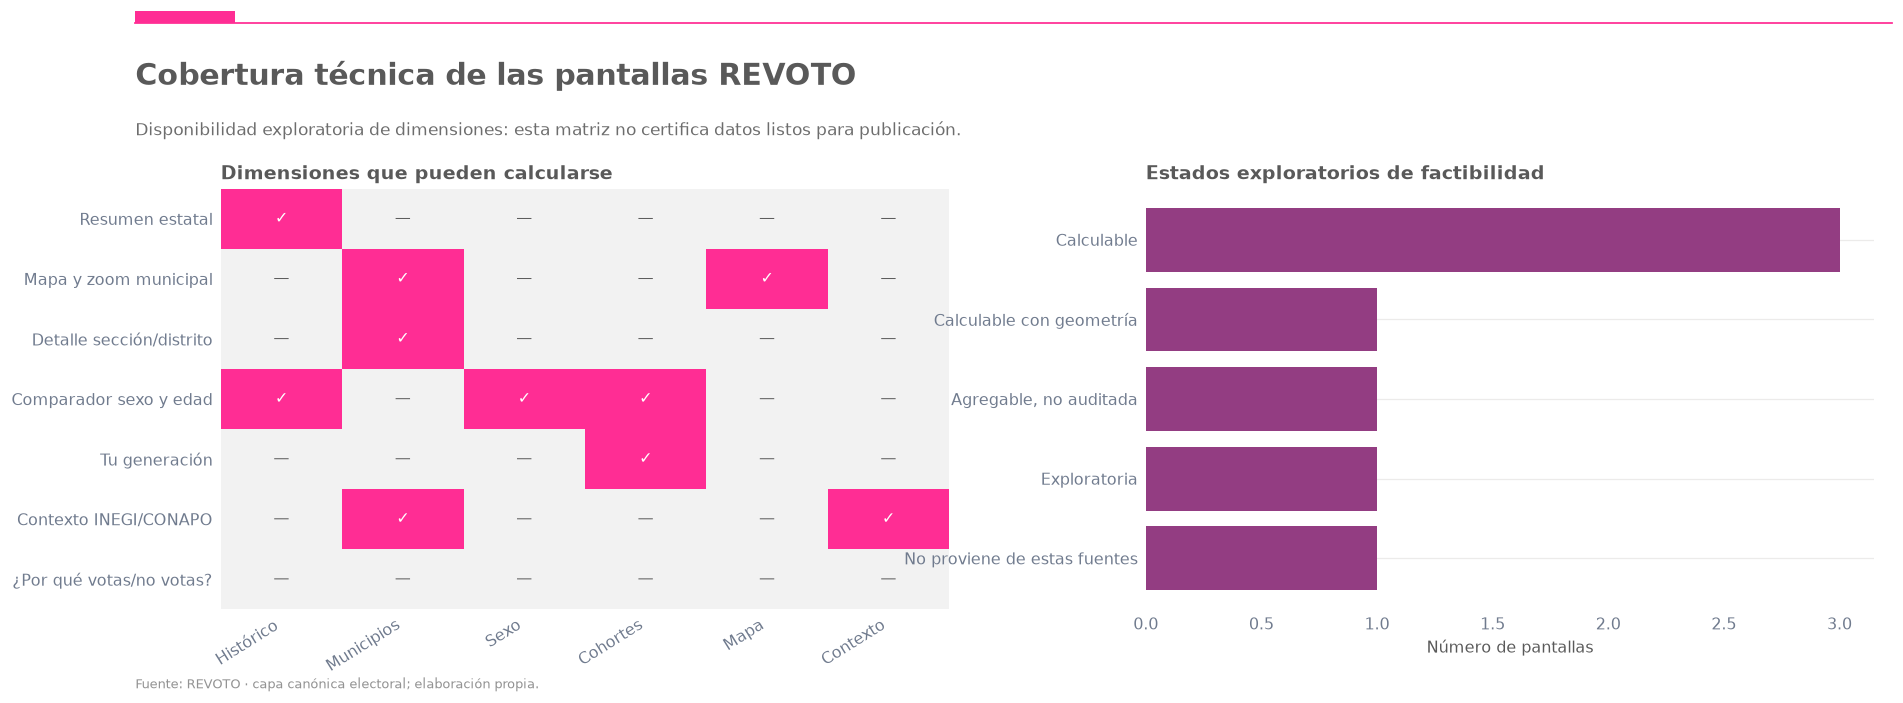

In [71]:
datos_ok=bool(len(hist))
municipios_ok=bool(len(municipal))
seccionales_ok=bool(cobertura.secciones_municipales.max()>0)
sex_ok=bool(len(sexo_df))
cohortes_ok=bool(len(cohortes))
mapas_ok=bool(mapa_info['cartografia_disponible'])
contexto_ok=bool(contexto_estado['disponible'])

cobertura_ui=pd.DataFrame([
    {'pantalla':'Resumen estatal','historia':datos_ok,'municipios':False,'sexo':False,'cohorte':False,'mapa':False,'contexto':False,
     'factibilidad_exploratoria':'Calculable' if datos_ok else 'Sin datos',
     'pendiente_publicacion':'Validación contra cifras oficiales, RN-05 y JSON'},
    {'pantalla':'Mapa y zoom municipal','historia':False,'municipios':municipios_ok,'sexo':False,'cohorte':False,'mapa':mapas_ok,'contexto':False,
     'factibilidad_exploratoria':'Calculable con geometría' if mapas_ok else 'Parcial',
     'pendiente_publicacion':'Cruces cartográficos por vigencia, cobertura geográfica, JSON/GeoJSON'},
    {'pantalla':'Detalle sección/distrito','historia':False,'municipios':seccionales_ok,'sexo':False,'cohorte':False,'mapa':False,'contexto':False,
     'factibilidad_exploratoria':'Agregable, no auditada',
     'pendiente_publicacion':'Geometría seccional, DEL/DEF, equivalencias y RN-05'},
    {'pantalla':'Comparador sexo y edad','historia':datos_ok,'municipios':False,'sexo':sex_ok,'cohorte':cohortes_ok,'mapa':False,'contexto':False,
     'factibilidad_exploratoria':'Calculable' if sex_ok else 'Parcial',
     'pendiente_publicacion':'Catálogos, cobertura por grupo, supresión de celdas'},
    {'pantalla':'Tu generación','historia':False,'municipios':False,'sexo':False,'cohorte':cohortes_ok,'mapa':False,'contexto':False,
     'factibilidad_exploratoria':'Exploratoria' if cohortes_ok else 'Sin datos',
     'pendiente_publicacion':'Edad abierta, cohortes, RN-05, textos responsables'},
    {'pantalla':'Contexto INEGI/CONAPO','historia':False,'municipios':municipios_ok,'sexo':False,'cohorte':False,'mapa':False,'contexto':contexto_ok,
     'factibilidad_exploratoria':'Parcial' if not contexto_ok else 'Calculable',
     'pendiente_publicacion':'Verificar censo_ref/conapo_ref, calidad de unión y aviso ecológico'},
    {'pantalla':'¿Por qué votas/no votas?','historia':False,'municipios':False,'sexo':False,'cohorte':False,'mapa':False,'contexto':False,
     'factibilidad_exploratoria':'No proviene de estas fuentes',
     'pendiente_publicacion':'Formulario voluntario, consentimiento, moderación, privacidad'}
])
mostrar(cobertura_ui[['pantalla','factibilidad_exploratoria','pendiente_publicacion']],15)
fig,axs=pagina('Cobertura técnica de las pantallas REVOTO',
    'Disponibilidad exploratoria de dimensiones: esta matriz no certifica datos listos para publicación.')
a,b=axs
cols=['historia','municipios','sexo','cohorte','mapa','contexto']
mat=cobertura_ui[cols].astype(int).to_numpy()
a.imshow(mat,cmap=plt.matplotlib.colors.ListedColormap(['#F2F2F2',VINO]),vmin=0,vmax=1,aspect='auto')
a.set_xticks(range(len(cols)),['Histórico','Municipios','Sexo','Cohortes','Mapa','Contexto'],rotation=32,ha='right')
a.set_yticks(range(len(cobertura_ui)),cobertura_ui.pantalla)
a.set_title('Dimensiones que pueden calcularse',loc='left',weight='bold')
a.grid(False)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]): a.text(j,i,'✓' if mat[i,j] else '—',ha='center',va='center',
                                        color='white' if mat[i,j] else GRIS,fontsize=10)
cuentas=cobertura_ui.factibilidad_exploratoria.value_counts()
b.barh(cuentas.index[::-1],cuentas.values[::-1],color=AZUL)
b.set_xlabel('Número de pantallas')
b.set_title('Estados exploratorios de factibilidad',loc='left',weight='bold')
cerrar(fig,'12_cobertura_wireframes')

## 9 · Resumen ejecutivo y recomendaciones

**Lectura para el equipo REVOTO.** Este bloque se genera a partir de las tablas calculadas; nunca se escriben aquí cifras que no hayan sido obtenidas de la fuente. La revisión editorial debe separar patrones descriptivos de hipótesis explicativas. Las cifras requieren conciliación con publicaciones oficiales antes de utilizarse públicamente.

In [72]:
if not hist.empty:
    ultimo_hist=hist.iloc[-1]
    inicio_hist=hist.iloc[0]
    mfinal=municipal[municipal.anio.eq(ANIO_FINAL)]
    cobertura_final=cobertura[cobertura.anio.eq(ANIO_FINAL)].iloc[0]
    msg=(f'### Ficha ejecutiva · {NOMBRE_ESTADO} ({EDO})\n'
         f'- **Periodo:** {int(inicio_hist.anio)}–{int(ultimo_hist.anio)}; {len(hist)} elecciones presentes.\n'
         f'- **Participación último año:** {ultimo_hist.tasa:.1%}, calculada mediante suma de votos/suma de LN.\n'
         f'- **Cambio respecto a elección anterior:** {ultimo_hist.cambio_pp:+.1f} pp.\n'
         f'- **Cobertura observada en {ANIO_FINAL}:** {int(cobertura_final.municipios)} municipios '
         f'y {int(cobertura_final.secciones_municipales)} pares municipio-sección.\n'
         f'- **Mapa real:** {"disponible" if mapas_ok else "pendiente de geometría válida"}. '
         f'**Contexto INEGI/CONAPO:** {"unible" if contexto_ok else "pendiente"}.\n'
         '- **Antes de publicar:** validar cobertura, cifras oficiales, cronología cartográfica, semántica de claves, '
         'RN-05, JSON y accesibilidad.\n')
    display(Markdown(msg))

recomendaciones=pd.DataFrame([
    {'prioridad':'Crítica','accion':'Conciliar años y niveles con cifras oficiales de la fuente, entidad y población correspondiente.'},
    {'prioridad':'Crítica','accion':'Implementar / auditar RN-05 en datasets publicados y evitar combinación de celdas protegidas.'},
    {'prioridad':'Alta','accion':'Revisar cobertura completa de municipios y secciones, periodos y comparabilidad de claves.'},
    {'prioridad':'Alta','accion':'Versionar geometrías municipales/seccionales y documentar crosswalks con vigencias.'},
    {'prioridad':'Alta','accion':'Generar agregados verificados para interfaces en JSON/GeoJSON, no exponer la tabla granular.'},
    {'prioridad':'Media','accion':'Verificar diccionarios de sexo, edades abiertas, tipo de sección, DEF y DEL.'},
    {'prioridad':'Media','accion':'Documentar año de referencia de INEGI y CONAPO y cobertura efectiva de uniones.'},
    {'prioridad':'Producto','accion':'Diseñar formulario voluntario y esquema independiente para motivos ciudadanos.'}
])
mostrar(recomendaciones,20)

### Ficha ejecutiva · Querétaro (22)
- **Periodo:** 2009–2024; 6 elecciones presentes.
- **Participación último año:** 59.6%, calculada mediante suma de votos/suma de LN.
- **Cambio respecto a elección anterior:** +9.7 pp.
- **Cobertura observada en 2024:** 18 municipios y 953 pares municipio-sección.
- **Mapa real:** disponible. **Contexto INEGI/CONAPO:** unible.
- **Antes de publicar:** validar cobertura, cifras oficiales, cronología cartográfica, semántica de claves, RN-05, JSON y accesibilidad.


,prioridad,accion
0,Crítica,Conciliar años y niveles con cifras oficiales ...
1,Crítica,Implementar / auditar RN-05 en datasets public...
2,Alta,Revisar cobertura completa de municipios y sec...
3,Alta,Versionar geometrías municipales/seccionales y...
4,Alta,Generar agregados verificados para interfaces ...
5,Media,"Verificar diccionarios de sexo, edades abierta..."
6,Media,Documentar año de referencia de INEGI y CONAPO...
7,Producto,Diseñar formulario voluntario y esquema indepe...


## 10 · Exportes y reproducibilidad

Las salidas se agrupan en `apps/pipeline/reportes/eda_outputs/edo=XX/` y no reemplazan archivos productivos. Se guardan tablas agregadas, métricas de calidad y metadatos en formatos legibles. Los PNG conservan la misma identidad visual del notebook. No se guardan datos individuales ni se crean datos sintéticos cuando falta una capa opcional.

In [73]:
def exportar_csv(df,archivo):
    if isinstance(df,pd.DataFrame) and len(df):
        ruta=SALIDA/archivo
        df.to_csv(ruta,index=False,encoding='utf-8-sig')
        ARCHIVOS_SALIDA.append(str(ruta))

exportar_csv(procedencia,'procedencia.csv')
exportar_csv(pd.DataFrame({'rol':list(MAPEO),'columna_fuente':list(MAPEO.values())}),'diccionario_columnas.csv')
exportar_csv(calidad,'calidad.csv')
exportar_csv(cobertura,'cobertura.csv')
exportar_csv(hist,'participacion_estatal.csv')
exportar_csv(comparacion_capas,'conciliacion_capas.csv')
exportar_csv(municipal,'participacion_municipal.csv')
exportar_csv(seccional,'participacion_seccional.csv')
exportar_csv(distrital,'participacion_codigos_del.csv')
exportar_csv(rank_corr.reset_index().rename(columns={'index':'anio'}),'estabilidad_rangos.csv')
exportar_csv(sexo_df,'participacion_sexo.csv')
exportar_csv(tipo_df,'participacion_tipo_seccion.csv')
exportar_csv(edad_df,'participacion_edad.csv')
exportar_csv(cohortes,'participacion_cohortes.csv')
exportar_csv(contexto_summary,'asociacion_contexto.csv')
exportar_csv(hallazgos_df,'hallazgos.csv')
exportar_csv(cobertura_ui,'cobertura_wireframes.csv')
exportar_csv(recomendaciones,'recomendaciones.csv')
metadatos={'estado':NOMBRE_ESTADO,'clave_estado':EDO,'periodos_observados':ANIOS_OBSERVADOS,
           'patron_electoral':PATRON,'archivos_electorales':len(ARCHIVOS_ELECTORALES),
           'mapping':MAPEO,'mapa':mapa_info,'contexto':contexto_estado,
           'umbral_ln_exploratorio':UMBRAL_LN_EXPLORATORIO,
           'advertencia':'EDA exploratorio; no certifica RN-05 ni cobertura oficial completa',
           'generado_utc':datetime.now(timezone.utc).isoformat()}
with (SALIDA/'metadatos.json').open('w',encoding='utf-8') as f:
    json.dump(metadatos,f,ensure_ascii=False,indent=2,default=str)
print(f'Exportes CSV: {len(ARCHIVOS_SALIDA)} | Figuras PNG: {len(list(FIGURAS.glob("*.png"))) if FIGURAS.exists() else 0}')
print('Destino:', SALIDA)
print('IMPORTANTE: ejecutar desde una raíz REVOTO válida y verificar cifras con las fuentes oficiales.')

Exportes CSV: 16 | Figuras PNG: 14
Destino: D:\Almacenamiento\CodingLab\projects\personal\ReVoto\apps\pipeline\reportes\eda_outputs\edo=22
IMPORTANTE: ejecutar desde una raíz REVOTO válida y verificar cifras con las fuentes oficiales.
